# SESI 4 — ETIKA DATA, PII, DAN BATASAN KERJA DENGAN AGENT
## Starter Notebook — Praktik Data Aman NusaMart

### Kasus yang akan kamu kerjakan
Tim Data Analyst NusaMart ingin membuat ringkasan **jumlah pelanggan berdasarkan kota dan segmen pelanggan**. Data pelanggan dari Sesi 3 sudah bersih, tetapi masih berisi informasi pribadi seperti nama, email, dan nomor telepon. Sebelum dipakai untuk analisis dengan bantuan Agent, tim harus menentukan data yang diperlukan, cara melindunginya, dan bukti pemeriksaannya.

**Tiga Praktik dan hasilnya:**

| Praktik | Apa yang kamu lakukan? | Output resmi S4 |
|---|---|---|
| **1 — Kenali Risiko** | Periksa 8 kolom dan putuskan risiko tiap kolom | **Catatan Audit PII** pada `01_PII_Audit` |
| **2 — Tentukan Penggunaan & Izin** | Tentukan teknik perlindungan dan batas izin Agent | **Checklist Etika Data** pada `02_Ethics_Permission` |
| **3 — Lindungi & Periksa** | Jalankan kode perlindungan dan enam tes pemeriksaan | **Skrip Masking PII Teruji** pada Notebook, didukung catatan `03_Verification_Evidence` |

**Satu kasus, satu workspace:** gunakan folder `Bootcamp_Data_Analyst` dari Sesi 3. File sumber adalah `data/processed/nusamart/customers_clean.csv`. Jangan mengedit atau mengganti file sumber. Buka **`S4_NusaMart_Safe_Data_Working_Paper.xlsx`** bersama Notebook ini.

### Baru pertama kali menggunakan Python?
Kamu **tidak perlu menulis kode dari awal**. Notebook adalah dokumen yang berisi teks penjelasan dan *code cell* (kotak kode Python). Kita akan menggunakan empat petunjuk yang sama sampai selesai:

- 🟢 **RUN** — klik ▶ di kiri kotak kode, tunggu sampai hasilnya muncul.
- 🟡 **EDIT** — ubah **hanya teks `TODO`** pada **Section 5**. Jangan mengubah tanda kutip, koma, atau nama kolom.
- 🔵 **CHECK** — baca hasil. `PASS` berarti pemeriksaan tertentu berhasil; `FAIL` atau `NOT READY` berarti perlu diperiksa lagi.
- 📝 **RECORD** — isi Working Paper pada sheet dan sel yang disebutkan. Jika tertulis **CHECK SAJA**, tidak perlu mengisi Excel.

**Istilah:** *Praktik* = kelompok tugas, *Langkah* = petunjuk untuk peserta, *Section 0–15* = nomor bagian dalam Notebook. Urutkan pengerjaan dari atas ke bawah. **Jangan langsung klik Run All**, supaya kamu sempat memahami hasilnya satu per satu.

> **Aturan keamanan:** Jangan unggah data pelanggan mentah ke layanan AI atau internet; jangan membagikan screenshot yang memperlihatkan identitas pelanggan; jangan menimpa sumber S3. Pengaturan izin Agent pada latihan ini **berupa rencana/simulasi**, bukan mengubah hak akses aplikasi. Masking dan SHA-256 bukan jaminan data sudah sepenuhnya anonim.

**Catatan gambar panduan:** gambar dibuat untuk membantu mengikuti langkah. Jika tampilan VS Code berbeda, ikuti nama Section dan teks instruksi Notebook. Gambar Excel pada panduan menggunakan susunan kolom Working Paper terbaru.

> **Cara membayangkan tugasnya:** seperti menyiapkan salinan daftar pelanggan untuk analisis. Periksa informasi pribadi, tetapkan bagian yang boleh digunakan, lindungi salinannya, lalu cek hasil. **Data mentah tidak diberikan kepada Agent dalam latihan ini; Python memproses data secara lokal.**



## PETA CEPAT — Hasil Notebook dicatat di sheet mana?

**File Excel:** `S4_NusaMart_Safe_Data_Working_Paper.xlsx` (nama tanpa nomor versi). Buka tab **`00_Panduan_Peserta`** lebih dulu. Keputusan Praktik 1 dan 2 **dibuat oleh peserta**, bukan disalin otomatis dari Python; Praktik 3 mencatat **output pemeriksaan sebenarnya**.

| Section Notebook | Tugas dan hasil yang dibaca | Isi Working Paper |
|---|---|---|
| **0–2** | Temukan workspace, baca 215 baris / 8 kolom, catat kondisi sumber | **CHECK SAJA** — belum ada isian |
| **3** | Tabel profil delapan kolom | `01_PII_Audit` → **B6:E13**; `email` baris 11 sudah contoh |
| **4** | Salinan kerja siap | **CHECK SAJA** |
| **5** | Tentukan cara perlindungan dan izin, lalu Review Gate | `02_Ethics_Permission` → **B6:D13** dan **B18:D21**. Setelah mengisi Excel, salin pilihan kode ke `TODO` Section 5 |
| **6** | Fungsi perlindungan siap | **CHECK SAJA** |
| **7–8** | Perlindungan diterapkan; lihat teknik dan ringkasan | `03_Verification_Evidence` → **VT-05 / D10:E10** |
| **9** | Rencana lokasi penyimpanan, belum menyimpan file akhir | **CHECK SAJA** |
| **10** | Apakah file sumber S3 berubah? | **VT-02 / D7:E7** |
| **11** | Apakah nilai pribadi mentah target masih ditemukan? | **VT-01 / D6:E6** |
| **12** | Apakah jumlah baris dan ID tetap valid? | **VT-03 / D8:E8** dan **VT-04 / D9:E9** |
| **13** | Apakah informasi untuk analisis tetap berguna? | **VT-06 / D11:E11** |
| **14–15** | Simpan bukti dan periksa hasil akhir | **CHECK SAJA**; pastikan VT-01–VT-06 sudah diisi dari output aktual |

**Di sheet Praktik 3:** kolom **D = Hasil dari Notebook**, **E = Status**, **F = Catatan jika bermasalah**. Kolom C (hasil yang seharusnya) dan G (lokasi Section) sudah tersedia. **Jangan mengisi PASS sebelum RUN.** Urutan kode VT di Excel tidak sama dengan urutan Section Notebook.

**Checkpoint akhir:** `READY` menunjukkan kelengkapan isian Excel; `SIAP DICEK` berarti kombinasi pilihan lolos cek awal Excel; **`REVIEW GATE: PASS` dan `FINAL QUALITY GATE: PASS` harus berasal dari RUN Notebook**, bukan dipilih di Excel.


## PERSIAPAN — Siapkan data dan dua file latihan

**Tugas NusaMart:** memakai data pelanggan bersih S3 sebagai input, tanpa mengubahnya. Kamu akan membuka Notebook Python dan Working Paper Excel berdampingan. Ikuti Section 0–2 sebelum memulai Praktik 1.


#### **Panduan Visual — Mulai Praktik: Apa yang Akan Kita Kerjakan?** — Peta Praktik 1–3 dan tiga output resmi

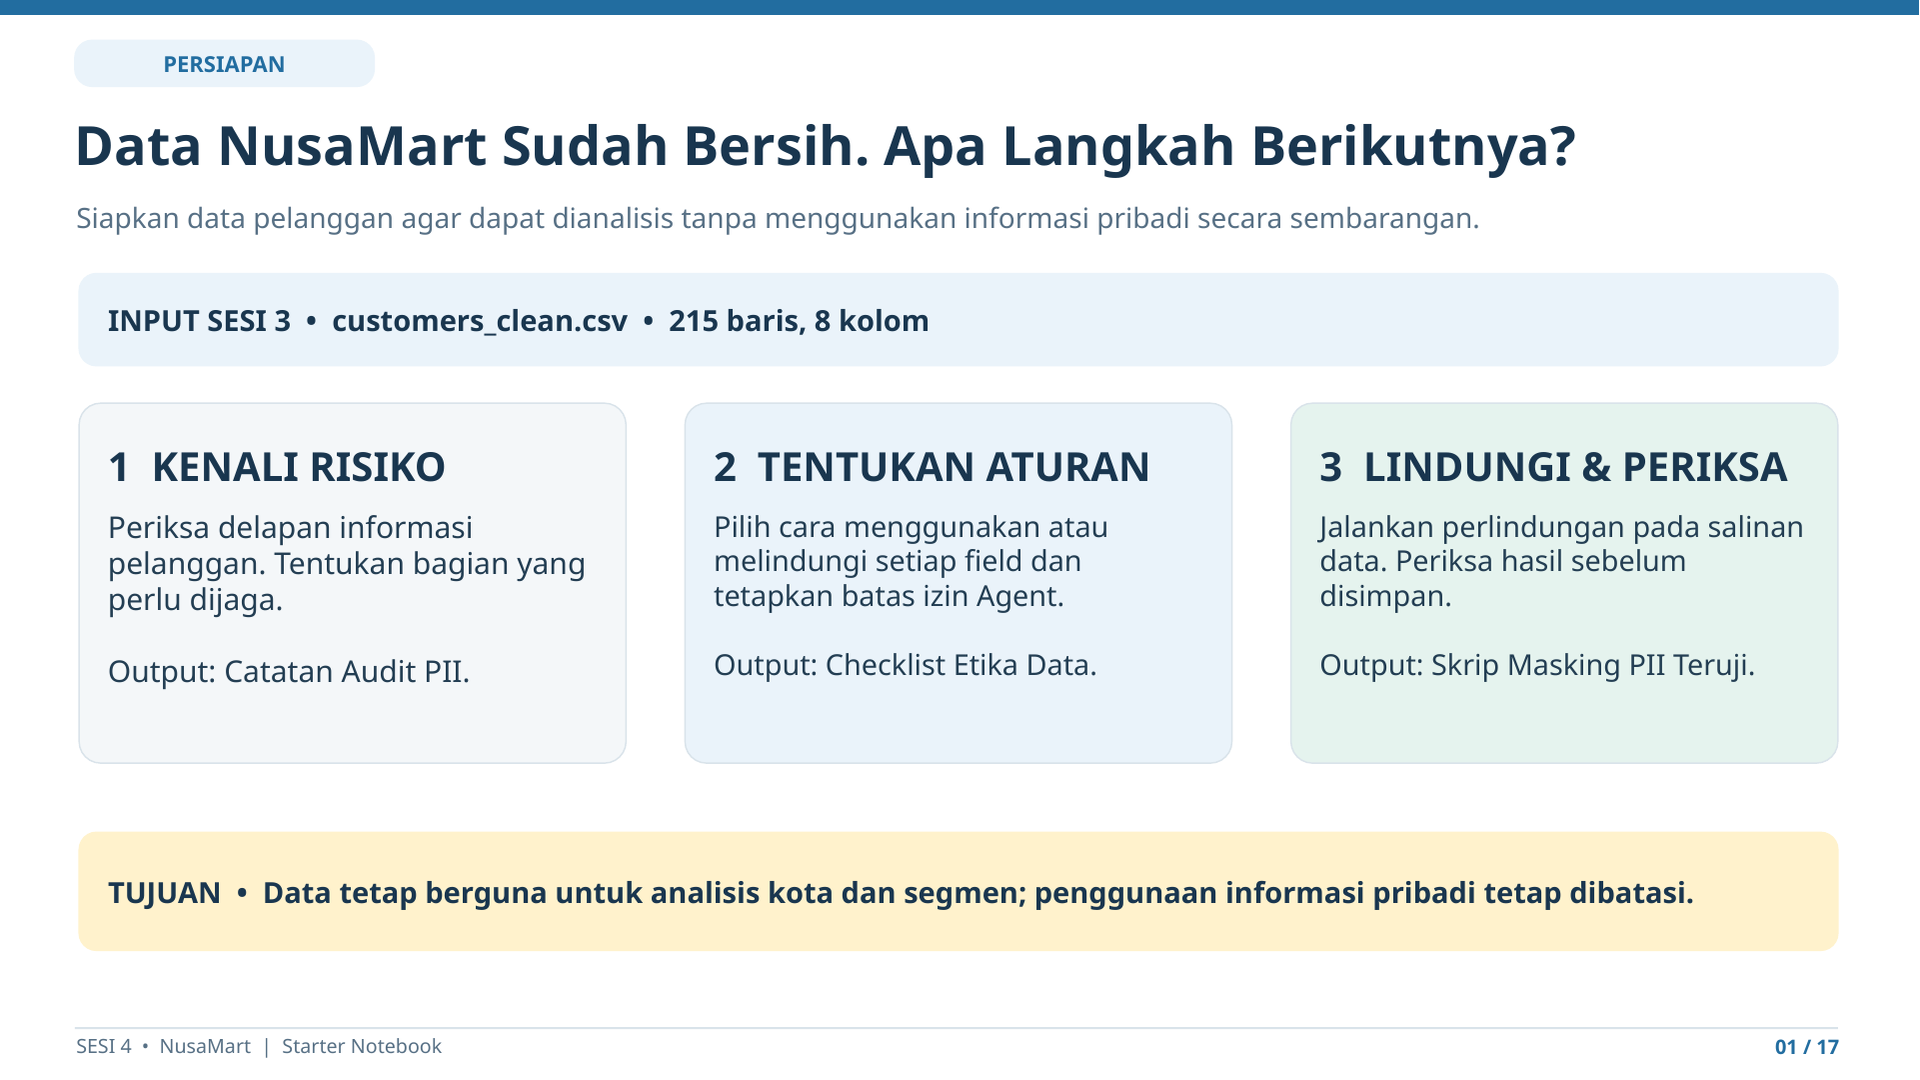


### Persiapan — buka folder dan kenali tampilan Notebook

1. Buka **VS Code → File → Open Folder**, pilih folder `Bootcamp_Data_Analyst` yang digunakan sejak Sesi 3.
2. Di panel **Explorer**, cari `data/processed/nusamart/customers_clean.csv`. Jika tidak ada, jangan membuat file pengganti; periksa lokasi file dari S3, lalu minta bantuan trainer jika masih belum ditemukan.
3. Buka **`S4_NusaMart_Safe_Data_Starter.ipynb`**. Buka juga **`S4_NusaMart_Safe_Data_Working_Paper.xlsx`** di Excel, lalu pilih tab `00_Panduan_Peserta`.
4. **Kenali dua jenis kotak Notebook:** kotak *Markdown* berisi penjelasan; kotak *Code* berisi instruksi Python dan biasanya memiliki tombol **▶** di samping.
5. Jika VS Code meminta **Select Kernel**, pilih kernel Python yang disiapkan untuk kelas. Jika belum tersedia, minta bantuan trainer jika pilihan kernel belum tersedia; jangan menginstal paket sembarangan.
6. Jalankan code cell **Section 0 → 1 → 2** satu per satu. Setelah satu RUN, tunggu hasil muncul di bawahnya sebelum lanjut.

🔵 **CHECK:** `PROJECT ROOT: FOUND`, `LOAD CHECK: PASS` dan `SOURCE SNAPSHOT: CAPTURED`. Dataset latihan memiliki **215 baris dan 8 kolom**.

📝 **RECORD:** belum perlu mengisi Excel. Persiapan hanya memastikan file dan Notebook siap.

**Jika gagal:** `PROJECT ROOT` tidak ditemukan → periksa folder yang dibuka. `SCHEMA CHECK` gagal → pastikan file berasal dari Sesi 3. Jangan mengubah nama kolom agar sekadar terlihat PASS.


#### **Panduan Visual — Persiapan: Buka File dan Jalankan Notebook** — Buka VS Code dan RUN Section 0–2

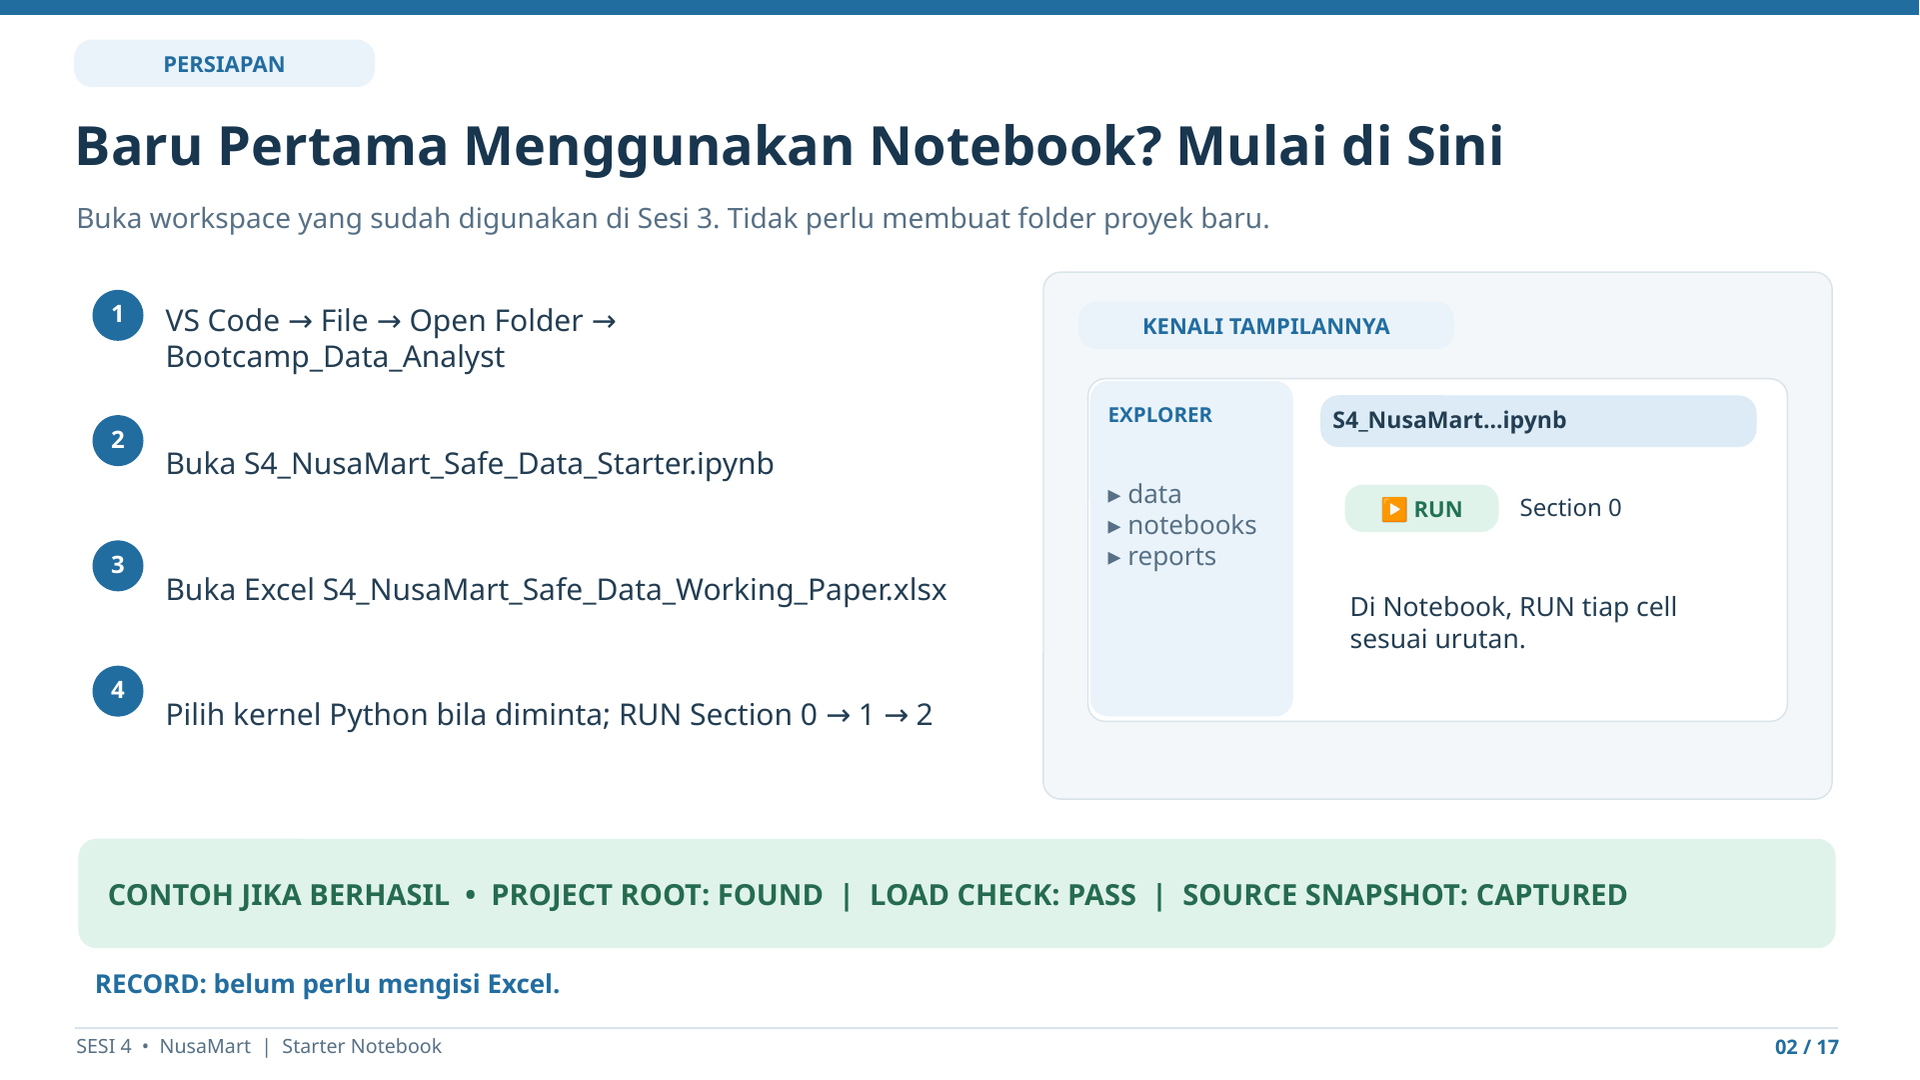


### Section 0 — Temukan folder kerja NusaMart

**Apa yang dilakukan kode?** Notebook mencari folder `Bootcamp_Data_Analyst` dan lokasi file pelanggan S3. Kamu tidak perlu memahami isi kode pencarian folder.

🟢 **RUN:** klik ▶ pada cell di bawah. **Jangan EDIT** kecuali folder belum ditemukan dan trainer membantu memastikan lokasi yang benar pada `PROJECT_ROOT_OVERRIDE`.

🔵 **CHECK:** `PROJECT ROOT: FOUND` berarti folder berhasil ditemukan. Jika gagal, periksa folder VS Code dan periksa folder kerja dan sampaikan pesan error kepada trainer jika masih gagal.

📝 **RECORD:** **tidak perlu mengisi Excel** dari Section ini.


In [1]:
from pathlib import Path
import hashlib
import json
import re
import pandas as pd

EXPECTED_INPUT_REL = Path("data/processed/nusamart/customers_clean.csv")
PROJECT_ROOT_OVERRIDE = None  # HANYA JIKA PERLU: Path(r"C:\Users\Nama\Documents\Bootcamp_Data_Analyst")

def find_project_root(start=None, override=None):
    if override is not None:
        root = Path(override).expanduser().resolve()
        if not (root / EXPECTED_INPUT_REL).is_file():
            raise FileNotFoundError(
                "PROJECT ROOT: NOT FOUND — periksa folder pada PROJECT_ROOT_OVERRIDE.\n"
                f"Yang dicari: {root / EXPECTED_INPUT_REL}\n"
                "Solusi: buka workspace Bootcamp_Data_Analyst yang sudah ada; pastikan customers_clean.csv ada di data/processed/nusamart/."
            )
        return root
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for candidate in candidates:
        if (candidate / EXPECTED_INPUT_REL).is_file():
            return candidate
    for candidate in candidates:
        nested = candidate / 'Bootcamp_Data_Analyst'
        if (nested / EXPECTED_INPUT_REL).is_file():
            return nested
    raise FileNotFoundError(
        "PROJECT ROOT: NOT FOUND.\n"
        "File harus tersedia di: Bootcamp_Data_Analyst/data/processed/nusamart/customers_clean.csv\n"
        "Solusi: buka folder Bootcamp_Data_Analyst di VS Code, atau isi PROJECT_ROOT_OVERRIDE sesuai contoh pada Section 0."
    )

PROJECT_ROOT = find_project_root(override=PROJECT_ROOT_OVERRIDE)
INPUT_PATH = PROJECT_ROOT / EXPECTED_INPUT_REL
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'sesi_04'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print('PROJECT ROOT: FOUND')
print('PROJECT_ROOT:', PROJECT_ROOT)
print('INPUT_PATH:', INPUT_PATH)
print('OUTPUT_DIR:', OUTPUT_DIR)

PROJECT ROOT: FOUND
PROJECT_ROOT: C:\Bootcamp\Bootcamp_Data_Analyst
INPUT_PATH: C:\Bootcamp\Bootcamp_Data_Analyst\data\processed\nusamart\customers_clean.csv
OUTPUT_DIR: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_04


#### Sesudah RUN Section 0 — Folder kerja sudah ditemukan?

**Contoh output jika berhasil:** `PROJECT ROOT: FOUND` serta baris `INPUT_PATH` dan `OUTPUT_DIR`.

- 🔵 **CHECK — Artinya:** Notebook sudah menemukan folder `Bootcamp_Data_Analyst`, lokasi `customers_clean.csv`, dan folder tempat hasil S4 akan disimpan. Ini **belum** berarti data sudah terbaca.
- **Jika `PROJECT ROOT: NOT FOUND`:** buka workspace yang sama seperti S3, lalu periksa apakah `data/processed/nusamart/customers_clean.csv` ada. Jalankan ulang Section 0. Jika masih gagal, tunjukkan **teks error tanpa data pribadi** kepada trainer.
- 📝 **RECORD:** belum perlu mengisi Excel. Lanjut Section 1.


### Section 1 — Baca data pelanggan yang akan diperiksa

**Apa yang dilakukan kode?** Membaca file `customers_clean.csv` hasil Sesi 3 dan memastikan delapan kolom yang dibutuhkan tersedia. Kode ini **tidak menampilkan daftar nama, email, atau nomor telepon asli**.

🟢 **RUN** cell berikut, tanpa mengubah kode.

🔵 **CHECK:** `LOAD CHECK: PASS`, **215 rows / 8 columns** pada dataset latihan. Jumlah dan daftar kolom ini menjadi acuan Praktik 1. Jika berbeda, periksa file sumber S3 dan minta bantuan trainer jika berbeda.

📝 **RECORD:** **belum mengisi Excel**. Saat Section 3 selesai, gunakan ringkasan kolom untuk `01_PII_Audit`.


In [2]:
EXPECTED_COLUMNS = [
    'customer_id','customer_name','city','customer_segment',
    'join_date','email','phone','customer_status'
]

def read_csv_robust(path):
    last_error = None
    for enc in ('utf-8-sig', 'utf-8', 'latin1'):
        try:
            # Telepon harus teks agar angka 0 di depan tidak hilang.
            return pd.read_csv(path, encoding=enc, dtype={'customer_id':'string','phone':'string','email':'string'}), enc
        except UnicodeDecodeError as err:
            last_error = err
    raise last_error

customers, detected_encoding = read_csv_robust(INPUT_PATH)
missing_columns = [col for col in EXPECTED_COLUMNS if col not in customers.columns]
if missing_columns:
    raise ValueError(f'SCHEMA CHECK: FAIL — kolom tidak ditemukan: {missing_columns}. Periksa file customers_clean.csv dari S3; jika masih gagal, minta bantuan trainer.')
if customers.empty:
    raise ValueError('LOAD CHECK: FAIL — customers_clean.csv kosong. Periksa file pelanggan dari S3; jika masih gagal, minta bantuan trainer.')
if customers['customer_id'].isna().any() or customers['customer_id'].duplicated().any():
    raise ValueError('KEY CHECK: FAIL — customer_id null/duplikat. Jangan ubah sumber S3. Tunjukkan pesan error kepada trainer tanpa data pribadi.')
print(f'LOAD CHECK: PASS | rows={len(customers)} | columns={len(customers.columns)} | encoding={detected_encoding}')
print('KOLOM:', ', '.join(customers.columns))
print('Preview data pribadi ditutup demi keamanan; gunakan Section 3 untuk ringkasan field.')

LOAD CHECK: PASS | rows=215 | columns=8 | encoding=utf-8-sig
KOLOM: customer_id, customer_name, city, customer_segment, join_date, email, phone, customer_status
Preview data pribadi ditutup demi keamanan; gunakan Section 3 untuk ringkasan field.


#### Sesudah RUN Section 1 — Apakah data berhasil dibaca?

**Contoh output jika berhasil:** `LOAD CHECK: PASS | rows=215 | columns=8 | ...`

- 🔵 **CHECK — Artinya:** Notebook berhasil membuka file pelanggan hasil S3. **215 baris** adalah jumlah pelanggan pada dataset latihan ini dan **8 kolom** adalah jenis informasi yang tersedia.
- **Mengapa penting?** Sebelum menentukan risiko, kita harus memastikan file sumber yang diperiksa benar. Bayangkan memeriksa daftar pelanggan: pastikan daftar yang dipakai memang daftar yang disiapkan tim.
- **Jika gagal (misalnya `SCHEMA CHECK: FAIL`, `LOAD CHECK: FAIL`, atau `KEY CHECK: FAIL`):** jangan mengedit file sumber S3. Periksa folder dan nama file. Jika tidak cocok, minta trainer memeriksa file asal tanpa mengirim PII mentah.
- 📝 **RECORD:** belum perlu mengisi Excel. Data ini akan dipelajari lebih lanjut pada Section 3.


### Section 2 — Simpan tanda pemeriksaan file sumber

**Mengapa penting?** Pada Sesi 5, file bersih dari S3 masih dibutuhkan untuk integrasi. Sebelum mengolah salinan data, Notebook mencatat tanda pengenal file sumber agar nanti dapat dibandingkan dengan kondisi akhirnya.

🟢 **RUN** cell berikut tanpa EDIT.

🔵 **CHECK:** `SOURCE SNAPSHOT: CAPTURED` berarti kondisi file awal sudah direkam. Kode panjang `file_sha256` tidak perlu dihafal atau disalin.

📝 **RECORD:** **tidak perlu dicatat sekarang**. Pemeriksaan file sumber yang sebenarnya dicatat di Praktik 3 setelah menjalankan **Section 10 → VT-02 / D7:E7**.

**Analogi singkat:** sama seperti mencatat kondisi dokumen asli sebelum diolah agar kita dapat memastikan dokumen tersebut tidak berubah setelah bekerja dengan salinannya.



In [3]:
def file_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            digest.update(chunk)
    return digest.hexdigest()

source_snapshot_before = {
    "path": str(INPUT_PATH.relative_to(PROJECT_ROOT)),
    "rows": int(len(customers)),
    "columns": int(customers.shape[1]),
    "file_sha256": file_sha256(INPUT_PATH),
    "file_size_bytes": int(INPUT_PATH.stat().st_size),
}

print("SOURCE SNAPSHOT: CAPTURED")
print(json.dumps(source_snapshot_before, indent=2))

SOURCE SNAPSHOT: CAPTURED
{
  "path": "data\\processed\\nusamart\\customers_clean.csv",
  "rows": 215,
  "columns": 8,
  "file_sha256": "9a45c83ae7d3e720544ee5abd754f328c344ec200027f0baa4bfee8c9afdc720",
  "file_size_bytes": 20682
}


#### Sesudah RUN Section 2 — Kondisi awal sumber sudah tercatat?

**Contoh output jika berhasil:** `SOURCE SNAPSHOT: CAPTURED`, diikuti keterangan `rows`, `file_sha256`, dan `file_size_bytes`.

- 🔵 **CHECK — Artinya:** Notebook sudah membuat *catatan pengenal* file sebelum diolah. Bayangkan mencatat kondisi dokumen asli terlebih dahulu agar setelah pekerjaan selesai kita bisa memastikan dokumen tersebut tidak berubah.
- **Apa arti `file_sha256`?** Itu adalah nilai pengenal hasil perhitungan file, bukan kata sandi dan bukan teknik untuk menyamarkan data pelanggan di langkah ini. Peserta **tidak perlu menghitungnya sendiri**.
- **Jika gagal:** pastikan Section 1 berhasil dan file masih ada. Jangan memodifikasi sumber untuk memaksa pemeriksaan lulus.
- 📝 **RECORD:** **CHECK SAJA**. Snapshot digunakan lagi pada Section 10; belum perlu menyalin nilai hash ke Working Paper.


---
## PRAKTIK 1 — Kenali Risiko Data Pelanggan
### Studi kasus: data mana yang diperlukan untuk analisis NusaMart?

Tim ingin menganalisis **jumlah pelanggan per kota dan segmen**, bukan menghubungi pelanggan satu per satu. Karena itu, informasi seperti `email` atau `phone` mempunyai risiko privasi yang berbeda dari kebutuhan analisis `city` dan `customer_segment`.

**PII** adalah informasi yang dapat mengenali orang. Identitas bisa terlihat langsung (misalnya email) atau menjadi lebih mudah dikenali ketika sejumlah informasi digabungkan. **Tugasmu bukan menghapus semua kolom**, melainkan menilai kebutuhan dan risiko masing-masing dari delapan kolom.

📝 **Output Praktik 1:** **Catatan Audit PII** pada sheet `01_PII_Audit`. Kamu akan melihat contoh baris email, lalu melanjutkan tujuh baris lain.

**Analogi singkat:** bayangkan memeriksa daftar pelanggan dan memberi tanda pada informasi yang harus dijaga. Di sini kamu membuat keputusan risiko menggunakan kolom data NusaMart, bukan menyensor data pada tahap audit.



#### **Panduan Visual — Pahami Dulu: Mengapa Data Pelanggan Perlu Diperiksa?** — Konsep PII langsung dan risiko kombinasi

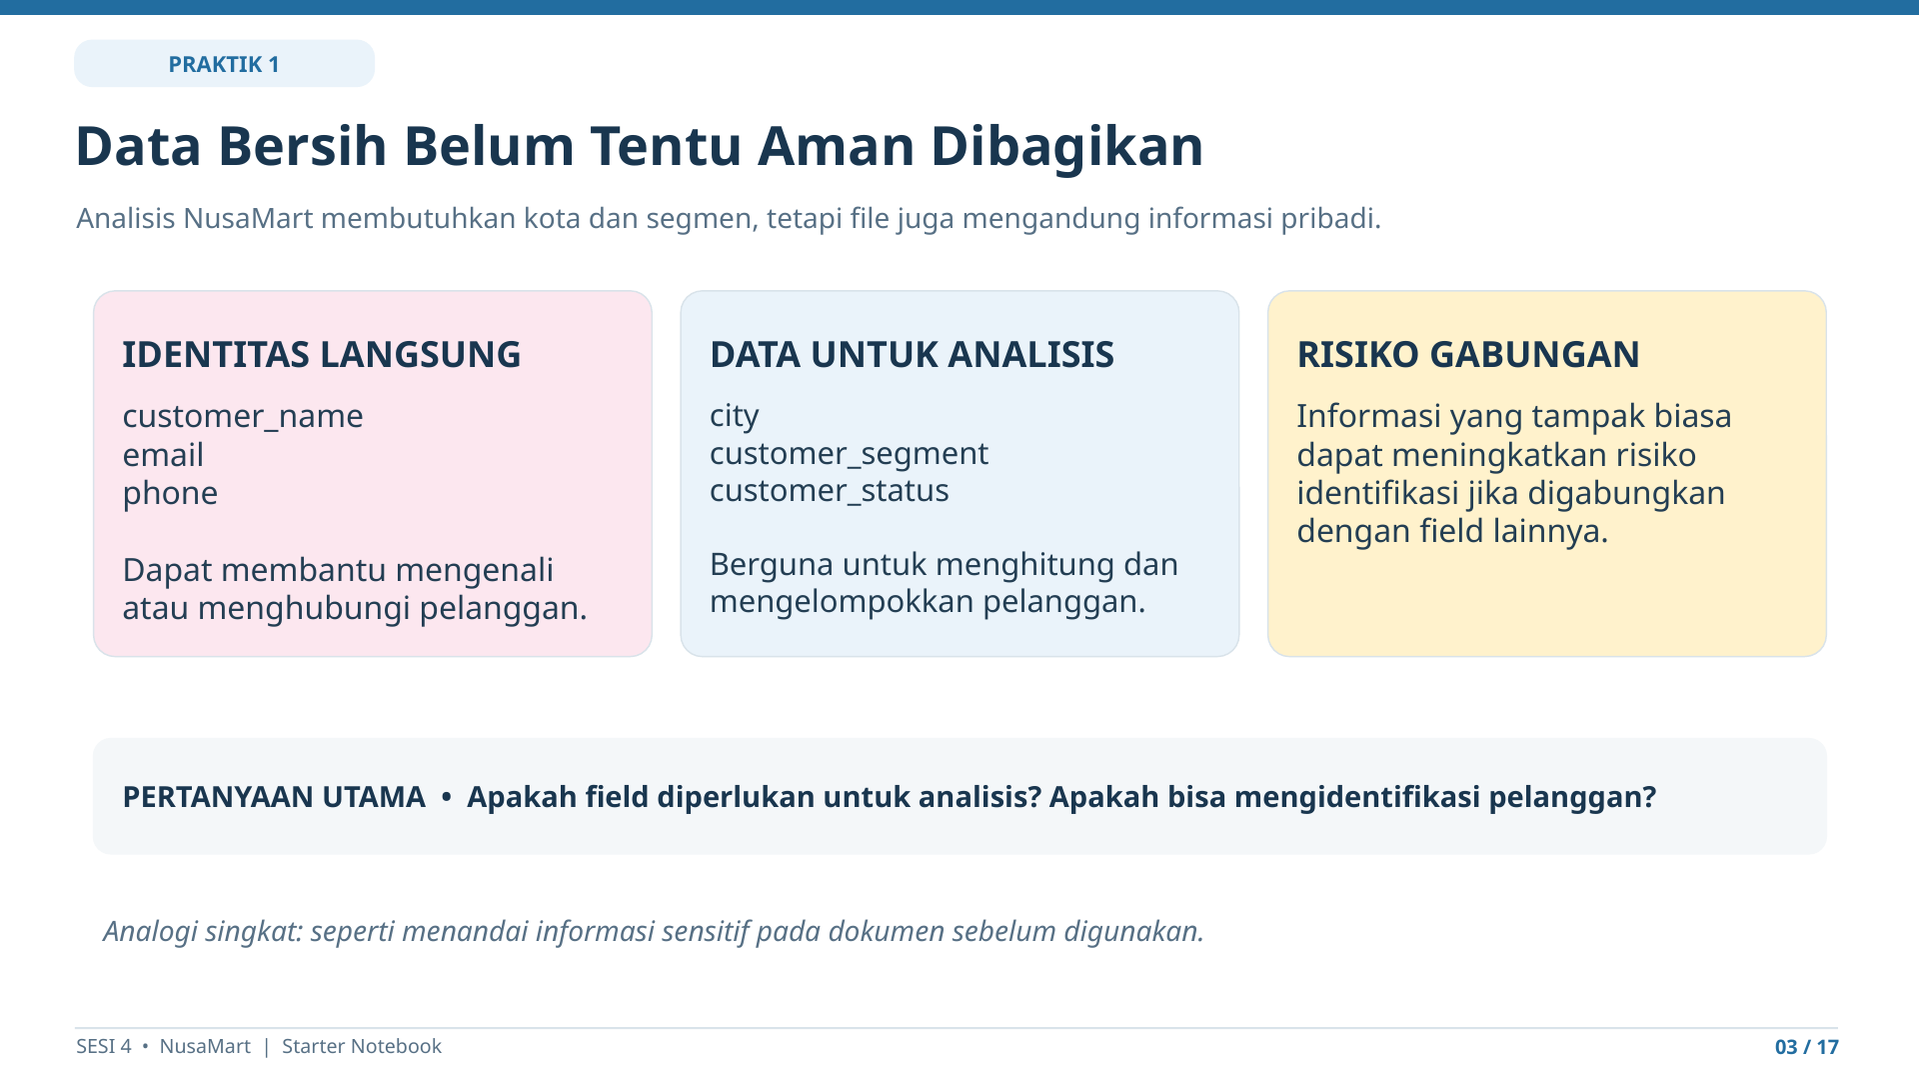


### Langkah 1 — Lihat informasi dalam delapan kolom pelanggan

1. Cari **Section 3** di bawah dan klik **▶ RUN** pada code cell.
2. Baca tabel hasilnya: `column` = nama kolom, `non_null` = data yang terisi, `missing` = jumlah kosong, `unique` = jumlah nilai berbeda. `dtype` menunjukkan bentuk data menurut Python; **tidak perlu kamu ubah**.
3. Temukan baris `email`, `city`, dan `customer_segment`. Dataset ini mempunyai **4 nilai kosong pada `customer_segment`**; kosong tidak otomatis berarti PII bocor.
4. Gunakan tabel sebagai **informasi pendukung** ketika mengisi audit.

🔵 **CHECK:** tabel delapan kolom muncul dan tidak memuat nilai pribadi mentah.

📝 **RECORD:** setelah melihat hasil, buka Excel → `01_PII_Audit` → **B6:E13**. Baca contoh baris `email` pada **B11:E11** sebelum mengisi sisanya.


#### **Panduan Visual — Langkah 1: Periksa Delapan Kolom Pelanggan** — RUN Section 3 dan baca tabel inspeksi delapan field

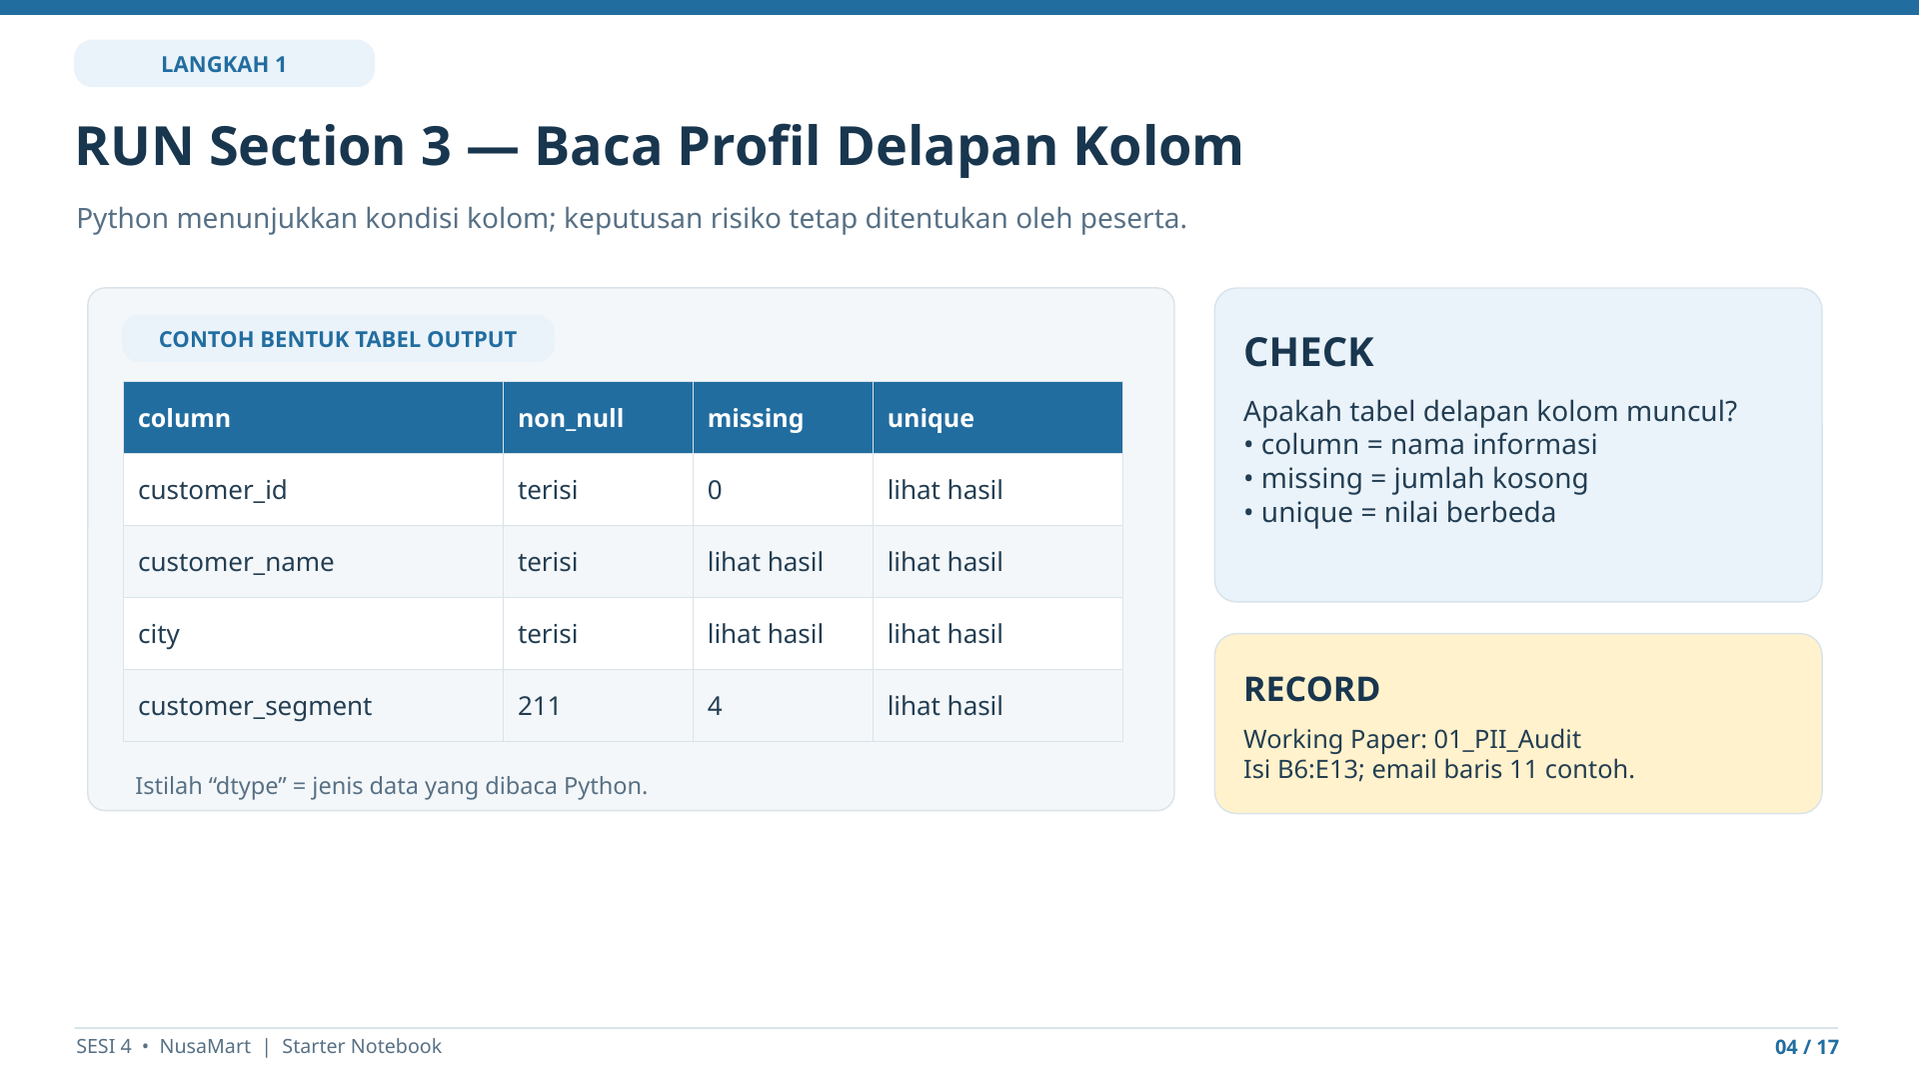


### Section 3 — Lihat ringkasan kolom tanpa menampilkan identitas pelanggan

**Apa yang dilakukan kode?** Menampilkan **nama kolom dan statistik ringkas**, bukan daftar nama/email/telepon asli.

🟢 **RUN** cell di bawah. **Tidak perlu EDIT**.

🔵 **CHECK:** muncul delapan nama kolom dengan jumlah kosong dan nilai unik.

📝 **RECORD:** `01_PII_Audit` → **B6:E13**. Informasi teknis berasal dari tabel ini; kategori risiko, alasan, dan keputusan tetap dibuat oleh **peserta**.


In [4]:
inspection = pd.DataFrame({
    "column": customers.columns,
    "dtype": [str(customers[c].dtype) for c in customers.columns],
    "non_null": [int(customers[c].notna().sum()) for c in customers.columns],
    "missing": [int(customers[c].isna().sum()) for c in customers.columns],
    "unique": [int(customers[c].nunique(dropna=True)) for c in customers.columns],
})

display(inspection)

,column,dtype,non_null,missing,unique
0,customer_id,string,215,0,215
1,customer_name,str,215,0,171
2,city,str,215,0,10
3,customer_segment,str,211,4,7
4,join_date,str,215,0,188
5,email,string,215,0,215
6,phone,string,215,0,215
7,customer_status,str,215,0,2


#### Sesudah RUN Section 3 — Membaca hasil profil data dan mengisi Praktik 1

**Yang muncul:** tabel delapan baris berisi `column`, `dtype`, `non_null`, `missing`, dan `unique`.

| Tulisan di output | Penjelasan sederhana |
|---|---|
| `column` | Nama informasi yang tersedia, misalnya `email` atau `city`. |
| `dtype` | Bentuk data menurut Python, misalnya teks atau tanggal yang sedang terbaca sebagai teks. |
| `non_null` | Jumlah baris yang memiliki isi pada kolom itu. |
| `missing` | Jumlah baris yang nilainya kosong. |
| `unique` | Jumlah nilai berbeda; **bukan otomatis jumlah pelanggan berisiko**. |

- 🔵 **CHECK — Artinya:** Kita sudah mengetahui kondisi dan jenis informasi pelanggan. Seperti menandai bagian sensitif pada daftar pelanggan, sekarang kamu perlu **menentukan sendiri** risiko tiap field. Python **tidak otomatis memutuskan** apakah suatu kolom aman dibagikan.
- 📝 **RECORD:** buka `01_PII_Audit` → **B6:E13**. Baris **11 / `email`** sudah contoh, lanjutkan tujuh baris lainnya. **B** kebutuhan, **C** jenis risiko, **D** alasan (termasuk risiko gabungan jika relevan), **E** usulan penanganan. Kolom **F/G** hanya kode audit dan sumber Notebook, **bukan isian peserta**.
- **Jika tabel tidak muncul:** periksa hasil Section 1, lalu jalankan kembali Section 3. Jangan menyalin contoh sebagai hasil untuk field lain tanpa menilai konteksnya.


### Langkah 2 — Pelajari contoh risiko `email` di Excel

Untuk analisis pelanggan per kota, email mentah tidak diperlukan. Email juga dapat mengidentifikasi pelanggan. Karena itu, **Working Paper** menyediakan contoh agar kamu tahu format pengisian yang diharapkan.

1. Buka sheet **`01_PII_Audit`**, cari field `email` pada **baris 11**.
2. Baca **B11 = `NO`**: email mentah tidak dibutuhkan untuk tujuan analisis ini.
3. Baca **C11 = `Direct PII`**: email adalah pengenal langsung.
4. Baca **D11**: satu alasan singkat tentang risikonya.
5. Baca **E11 = `PROTECT`**: usulan membuat bentuk terlindungi **untuk demonstrasi lokal**, bukan izin membagikan email asli.
6. Kolom F dan G adalah kode audit serta referensi Section; **tidak perlu diisi atau diubah peserta**.

📝 **RECORD:** **contoh email sudah tersedia**, jadi lanjutkan tujuh baris lain di B6:E13.


#### Panduan visual — Langkah 2 — Contoh email di Praktik 1

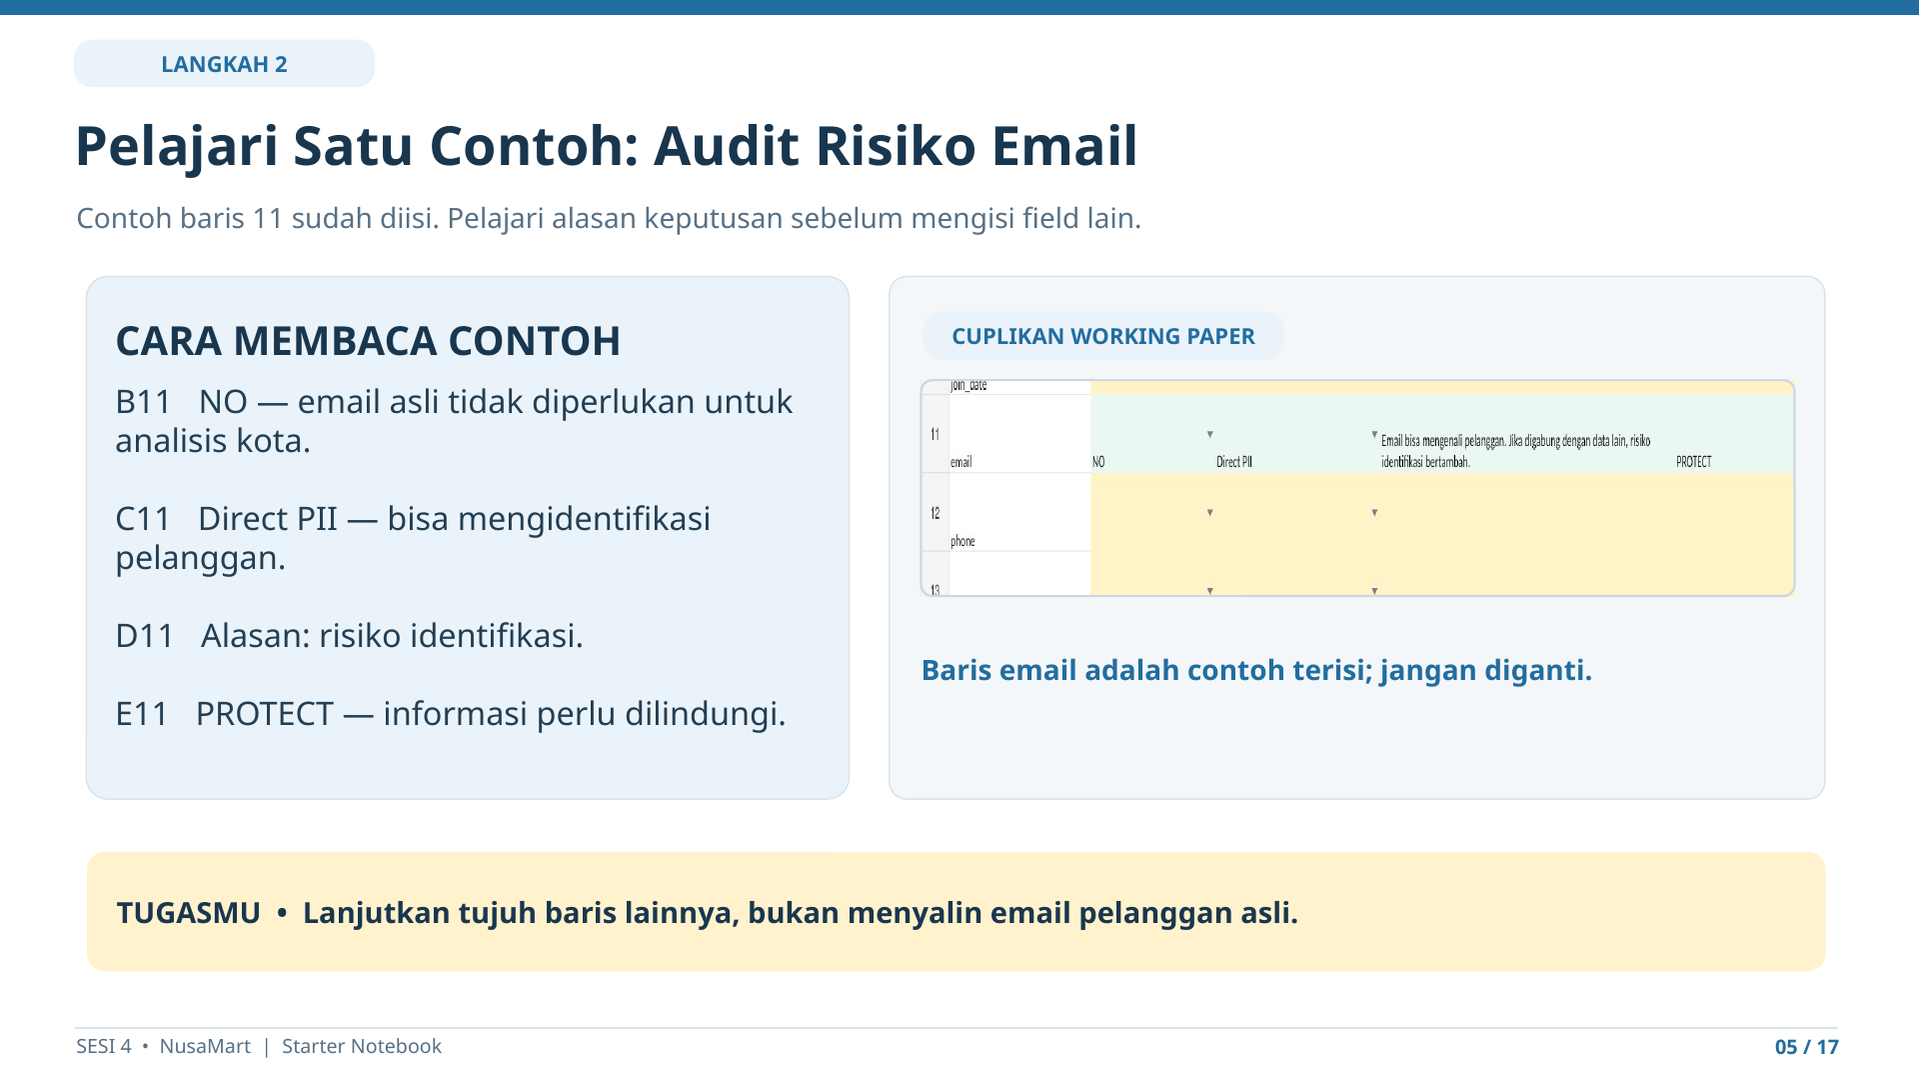

### Langkah 3 — Selesaikan audit tujuh kolom lain

1. Tetap di `01_PII_Audit`. Isi **B–E** pada baris **6–10 dan 12–13**. Baris email 11 adalah contoh terisi.
2. Untuk setiap field, tanyakan: **(a)** apakah dibutuhkan untuk analisis NusaMart, **(b)** apakah bisa mengenali pelanggan, **(c)** jika digabung dengan data lain apakah risikonya meningkat, **(d)** bagaimana mengelolanya?
3. Perhatikan `customer_id`: diperlukan untuk menghubungkan data pada **Sesi 5**, tetapi aksesnya tetap perlu dibatasi.
4. Berikan alasan singkat di **kolom D**; pilih opsi dari dropdown untuk B, C, E. Jangan hanya mengisi dropdown tanpa alasan.
5. Lihat **F15**. Jika `READY`, artinya isian lengkap untuk diperiksa, **belum berarti pemeriksaan teknis di Notebook lulus**.
6. **Simpan Excel**, lalu kembali ke Notebook dan RUN Section 4.

📝 **RECORD:** selesai pada `01_PII_Audit!B6:E13`. 🔵 **CHECK:** Section 4 menghasilkan `WORKING COPY: READY`.


#### Panduan visual — Langkah 3 — Audit tujuh field lain

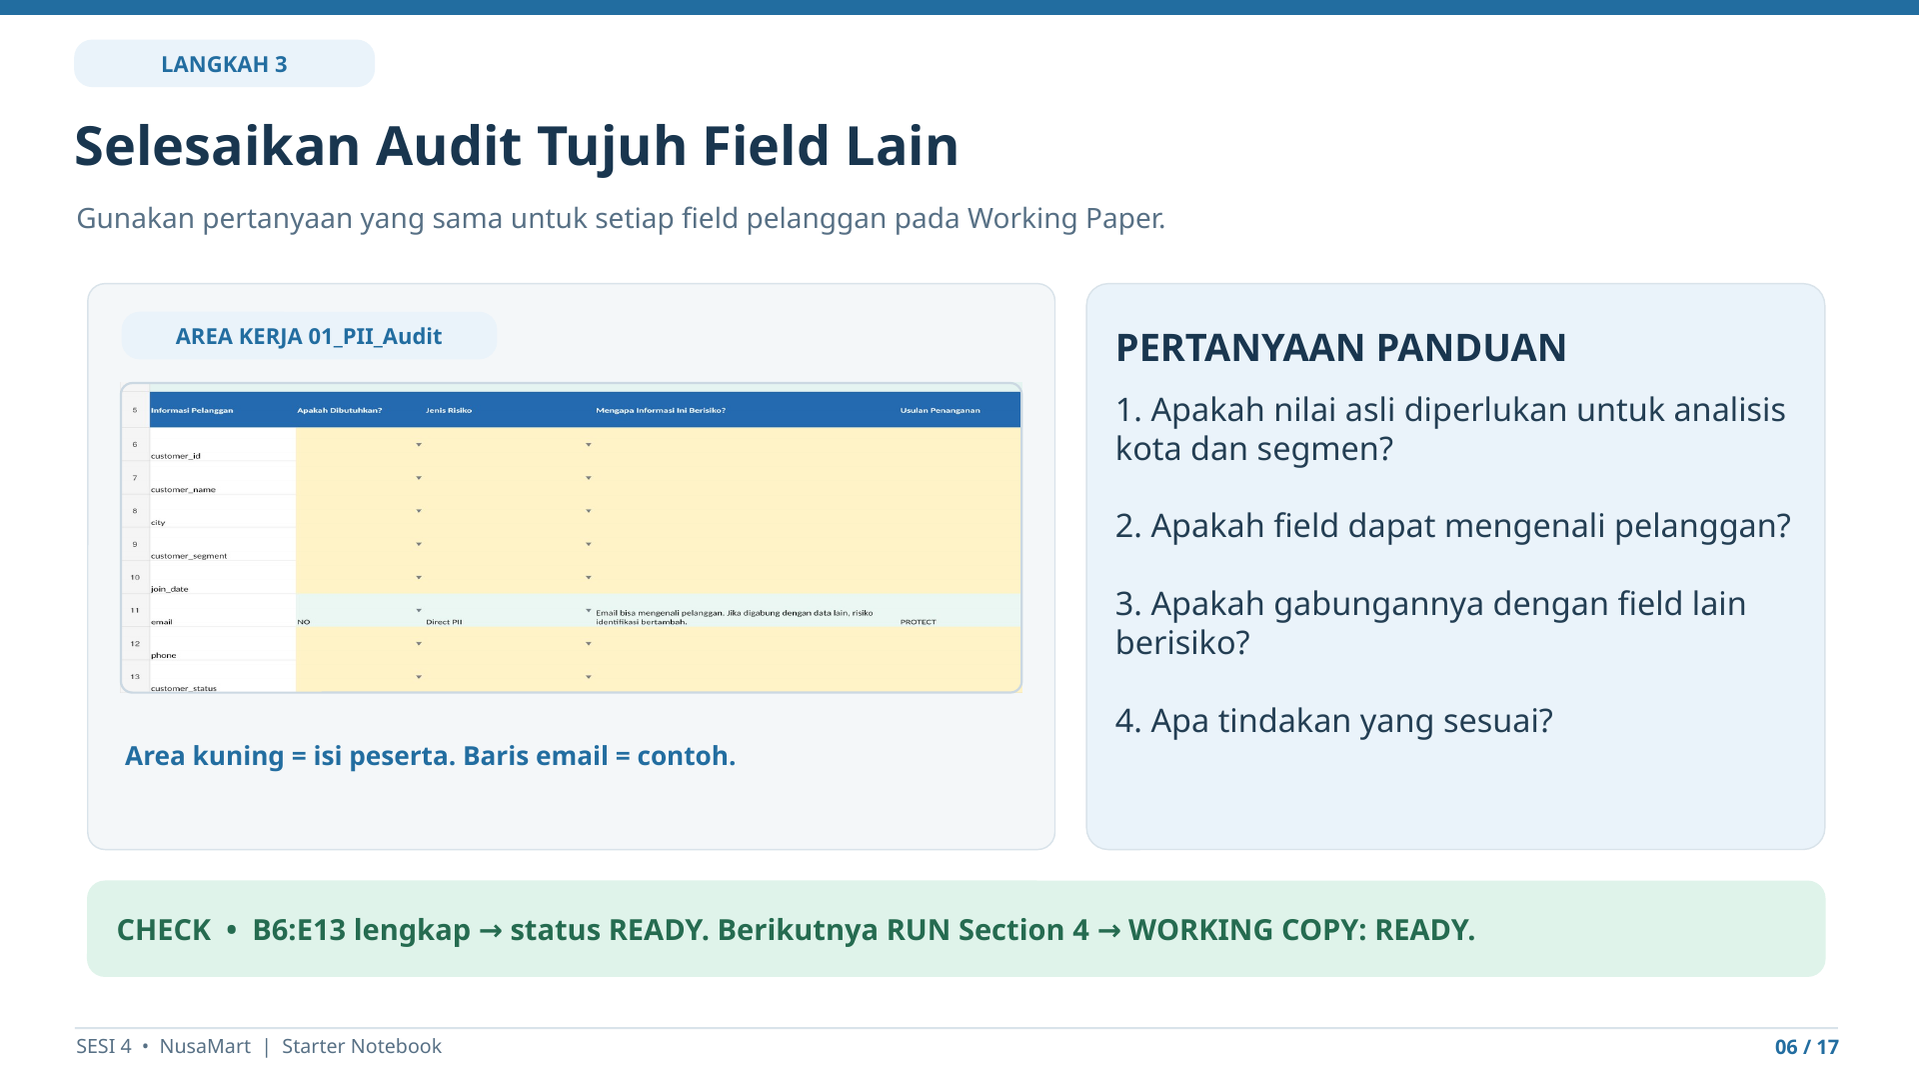

### Section 4 — Siapkan salinan data untuk praktik perlindungan

**Apa yang dilakukan kode?** Membuat salinan `customers_clean.csv` di memori komputer. Proses perlindungan nanti dilakukan pada salinan ini, **bukan mengganti file asli dari Sesi 3**.

🟢 **RUN** cell berikut, tanpa EDIT.

🔵 **CHECK:** `WORKING COPY: READY` berarti salinan kerja siap. Setelah itu lanjut ke Praktik 2.

📝 **RECORD:** **tidak perlu mengisi Excel** dari output Section 4.

**Analogi singkat:** kita bekerja pada salinan dokumen, bukan menulis langsung pada arsip aslinya.



In [5]:
working = customers.copy(deep=True)

assert working is not customers
assert len(working) == len(customers)
assert list(working.columns) == list(customers.columns)

print("WORKING COPY: READY")
print("Source tetap berada di:", INPUT_PATH)

WORKING COPY: READY
Source tetap berada di: C:\Bootcamp\Bootcamp_Data_Analyst\data\processed\nusamart\customers_clean.csv


#### Sesudah RUN Section 4 — Salinan kerja siap digunakan

**Contoh output:** `WORKING COPY: READY`.

- 🔵 **CHECK — Artinya:** Notebook membuat **salinan data di memori** untuk perlindungan. Bayangkan membuat salinan dokumen pelanggan agar dokumen asli tetap disimpan utuh. File `customers_clean.csv` asli **tidak diubah** oleh langkah ini.
- **Jika gagal:** periksa apakah Section 1 berhasil, kemudian jalankan lagi Section 4. Tidak perlu membuat file CSV baru.
- 📝 **RECORD:** **CHECK SAJA**. Setelah audit Praktik 1 berstatus `READY`, lanjut mengisi Praktik 2 pada Excel.


---
## PRAKTIK 2 — Tentukan Penggunaan Data dan Izin Agent
### Studi kasus: siapa boleh memakai informasi apa?

NusaMart ingin menganalisis **kota dan segmen**, bukan membagikan seluruh identitas pelanggan. Sebelum perlindungan dijalankan, kamu harus menentukan untuk **setiap field** apakah boleh dipakai, perlu dilindungi, aksesnya harus dibatasi, atau tidak boleh diberikan.

**Empat keputusan utama:**
- **`ALLOW`** — digunakan sesuai kebutuhan yang disetujui, tanpa teknik perlindungan tambahan (`KEEP`).
- **`PROTECT`** — bentuk asli diproses menjadi bentuk yang lebih terlindungi (contoh: `MASK_EMAIL`).
- **`RESTRICT`** — hanya digunakan dalam cakupan tugas/akses terbatas (contoh `customer_id` sebagai kunci relasi S5).
- **`DO_NOT_SHARE`** — tidak diberikan dalam hasil untuk tugas ini (contoh: nama pelanggan → `DROP`).

**Contoh untuk latihan ini:** email mentah tidak dibagikan. Versi maskerannya dipakai hanya untuk demonstrasi lokal. Kode izin Agent adalah **rencana izin untuk simulasi**, bukan pemberian akses otomatis pada layanan AI.

📝 **Output Praktik 2:** Checklist Etika Data pada `02_Ethics_Permission`, dilanjutkan EDIT keputusan di **Section 5**.

**Analogi singkat:** seperti memberi akses kepada seorang asisten hanya pada informasi dan folder yang diperlukan untuk pekerjaannya. Di Notebook ini, izin Agent **hanya dicatat dan diperiksa sebagai rencana**, bukan mengubah izin nyata aplikasi.



#### **Panduan Visual — Pahami Dulu: Apakah Semua Data Pribadi Harus Dihapus?** — Empat keputusan penggunaan data pada kasus NusaMart

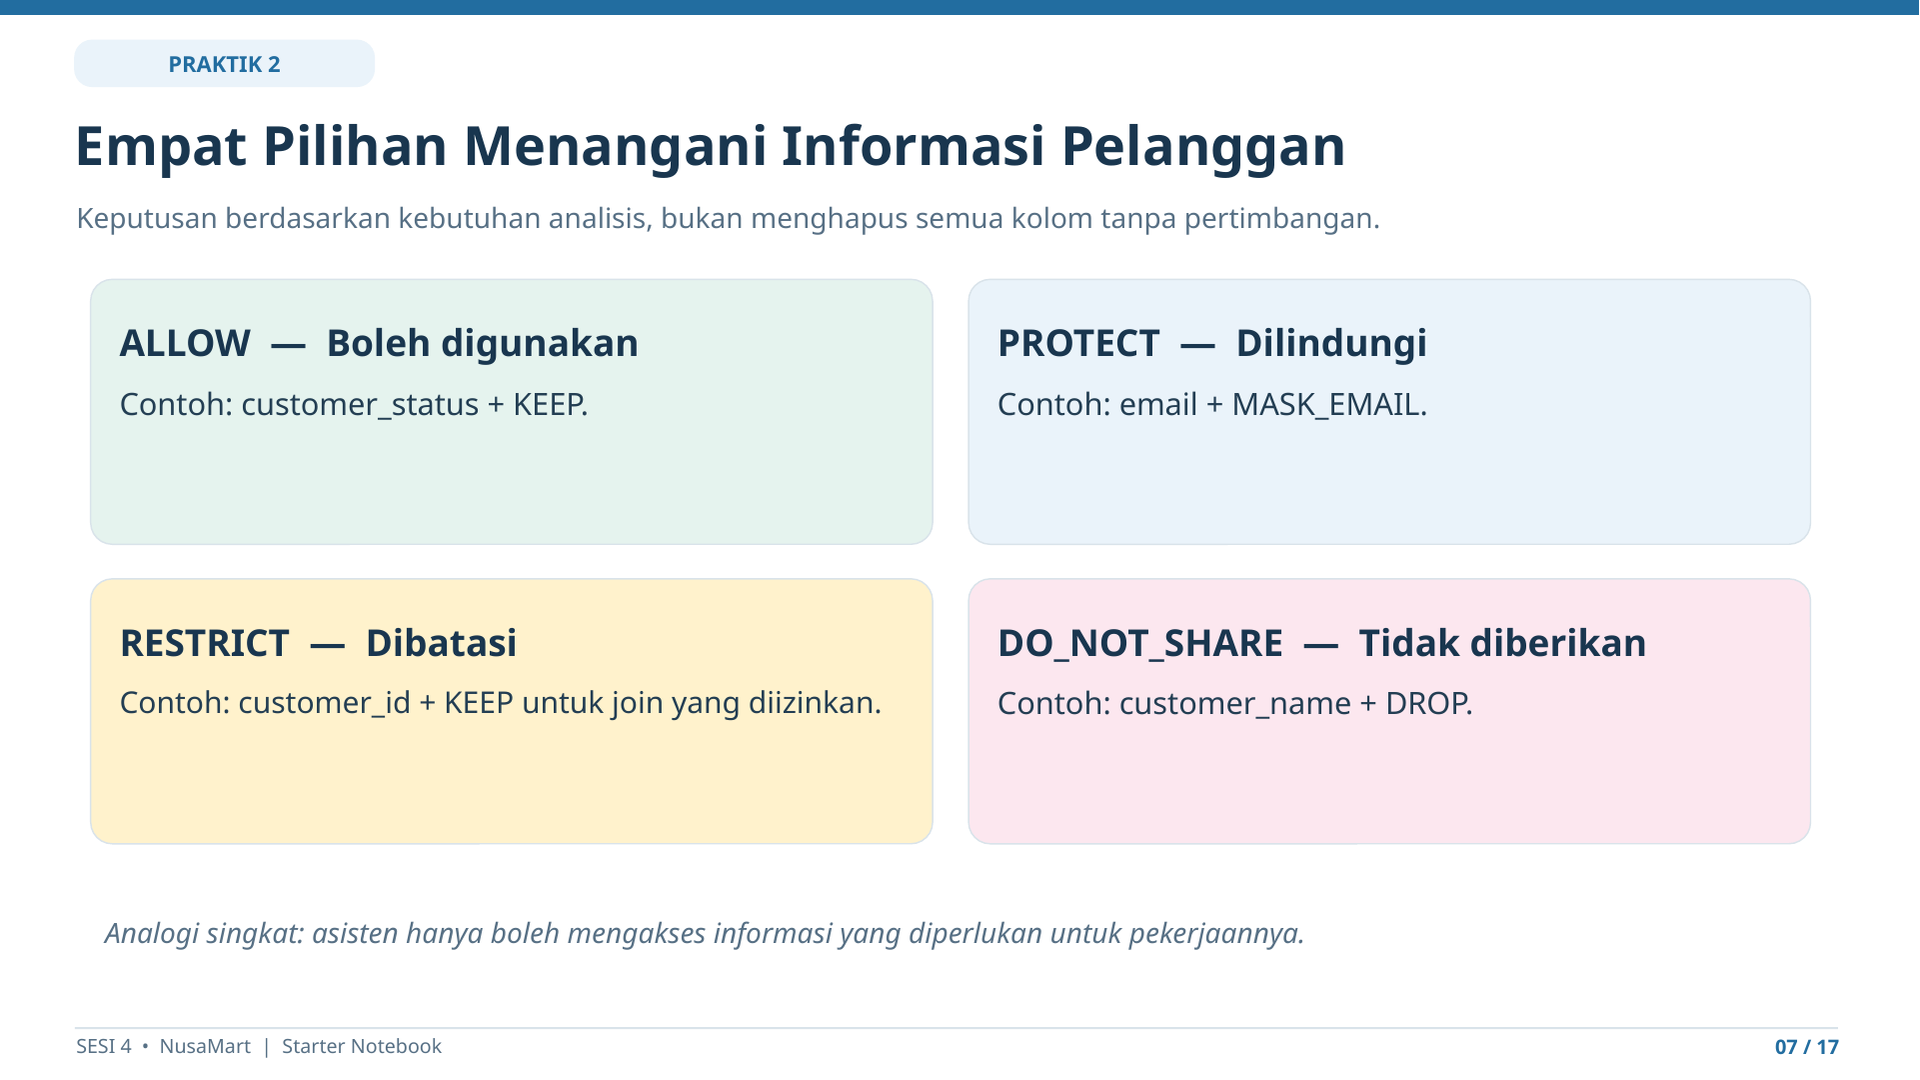


### Langkah 4 — Isi keputusan penggunaan data di Working Paper

1. Buka `02_Ethics_Permission` pada Working Paper. Lihat **bagian A, baris 6–13**.
2. Baca contoh **`email` baris 11**, yang sudah berisi `B11 = PROTECT`, `C11 = MASK_EMAIL` dan alasan pada `D11`.
3. Isi **B6:D10 dan B12:D13** untuk tujuh field lainnya:
   - **B** — keputusan penggunaan: `ALLOW` / `PROTECT` / `RESTRICT` / `DO_NOT_SHARE`.
   - **C** — teknik yang sesuai dengan jenis field (contoh `DROP`, `MASK_PHONE`, `GENERALIZE_RARE`, `KEEP`).
   - **D** — alasan singkat sesuai tujuan analisis NusaMart.
4. **E** adalah satu kolom **Hasil Cek (otomatis)**. `BELUM LENGKAP` → lengkapi B–D; `PERIKSA PILIHAN` → periksa kombinasi B dan C; `SIAP DICEK` → lanjut validasi di Notebook. **F** adalah kode referensi, bukan isian peserta.
5. Cocokkan dengan audit Praktik 1. Kode di Excel memakai **huruf besar yang sama** dengan Section 5 Notebook.

📝 **RECORD:** keputusan dan alasan pada **`02_Ethics_Permission!B6:D13`**. Jangan menyalin teks pelanggan asli ke alasan.


#### Panduan visual — Langkah 4 — Keputusan data pelanggan

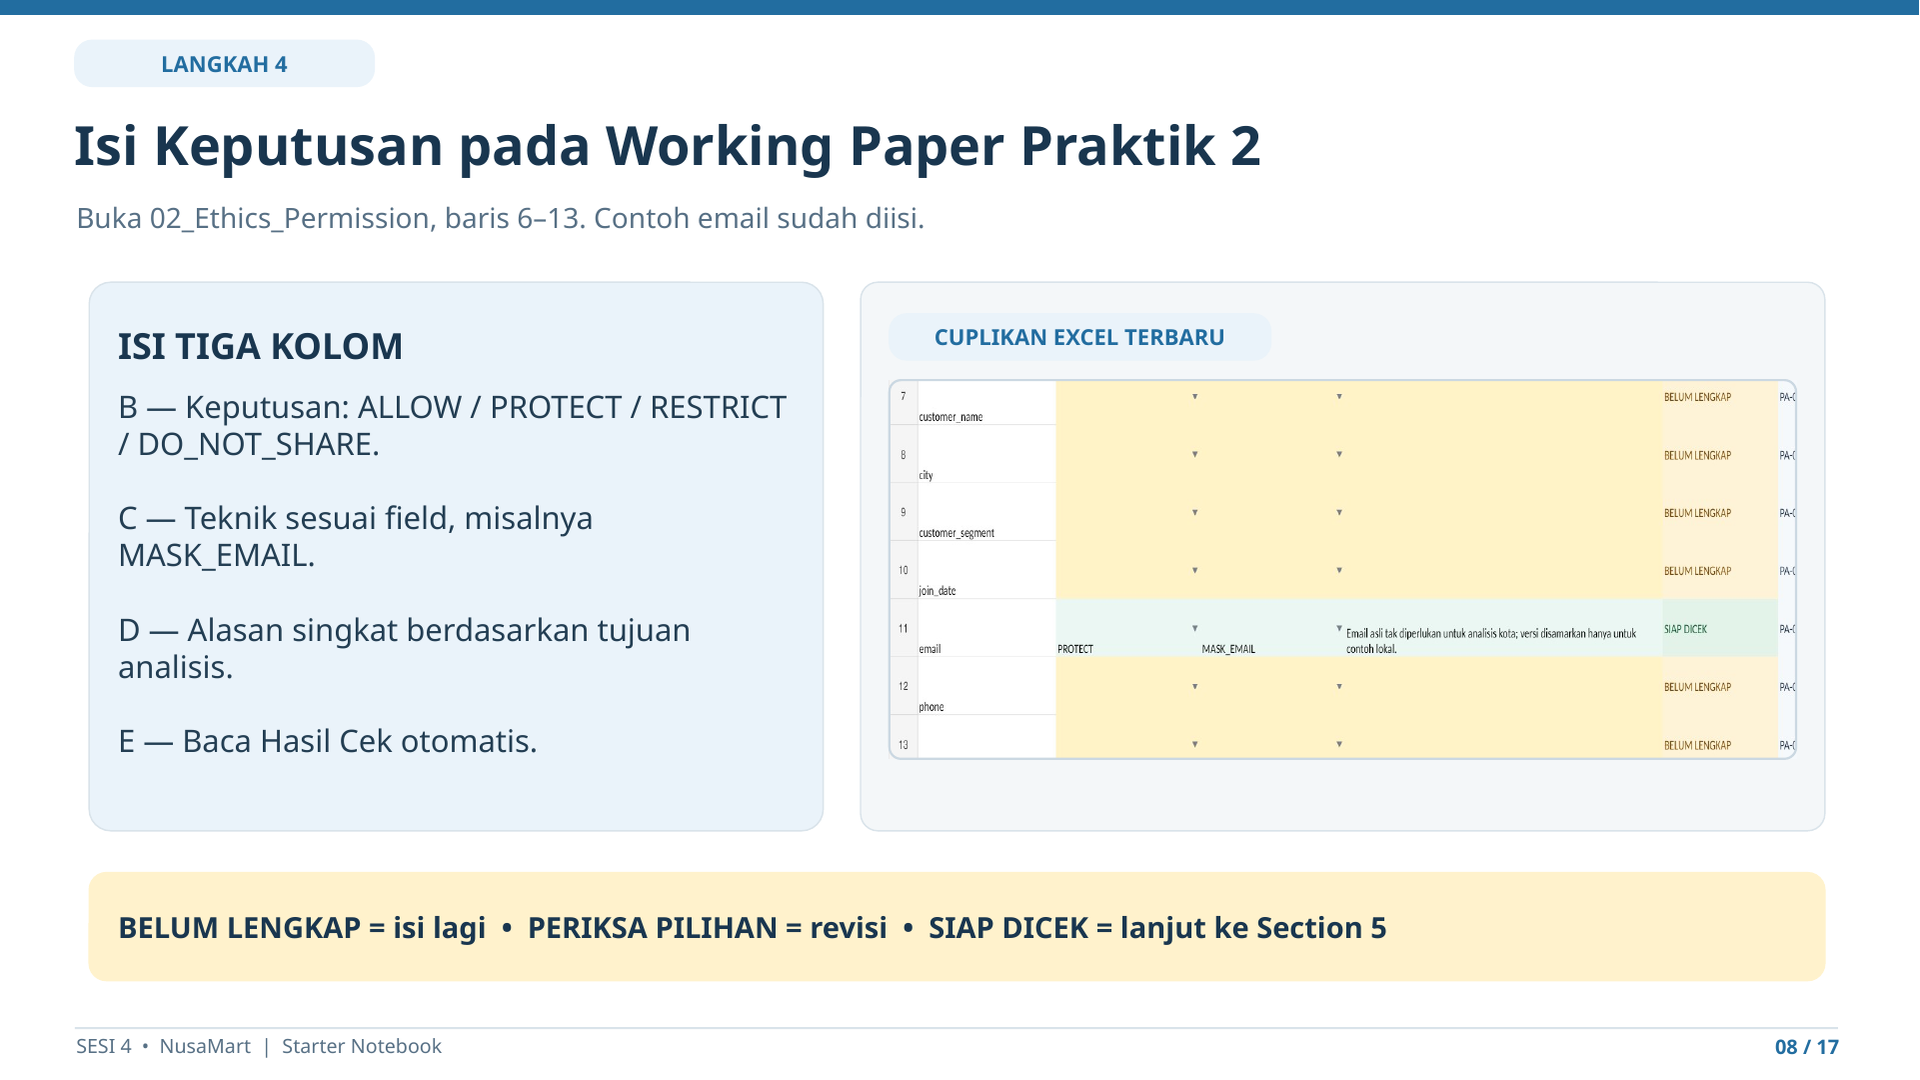

### Langkah 5 — Atur batas izin Agent

**Pertanyaannya:** untuk pekerjaan lokal S4 ini, Agent perlu membaca file mana, menyimpan hasil di mana, menjalankan kode di mana, dan apakah perlu internet? Prinsipnya **hanya akses yang diperlukan** (*least privilege*).

1. Masih di `02_Ethics_Permission`, cari **bagian B — izin Agent, baris 18–21**.
2. **Kolom B** = batas izin yang dipilih, **kolom C** = arti batasnya (sudah tersedia), **kolom D** = alasan singkat (kamu isi bila masih kosong).
3. **Baris 18 (Read)** sudah dicontohkan: **B18 = `S4_FILES_ONLY`**. Jangan menghapus contohnya.
4. **Baris 19 (Write)**: pilih `OUTPUT_S4_ONLY` dan berikan alasan mengapa hasil hanya disimpan pada folder output S4.
5. **Baris 20 (Terminal / Code)**: pilih `LOCAL_ONLY` dan berikan alasan mengapa cukup menjalankan kode lokal.
6. **Baris 21 (Network)** sudah dipatok **`DENY`**. Ini bukan tugas untuk diubah menjadi ALLOW. Akses internet tidak diperlukan.
7. Kolom **E–F** berisi hasil otomatis; kolom **G–H** referensi. Simpan Excel setelah keputusan selesai.

📝 **RECORD:** pada **B18:D21**, fokus lengkapi yang kosong pada **B19:D20**; contoh Read dan Network tetap tersedia. Berikutnya, pindahkan pilihan tersebut ke Section 5 Notebook.


#### Panduan visual — Langkah 5 — Batasi izin Agent

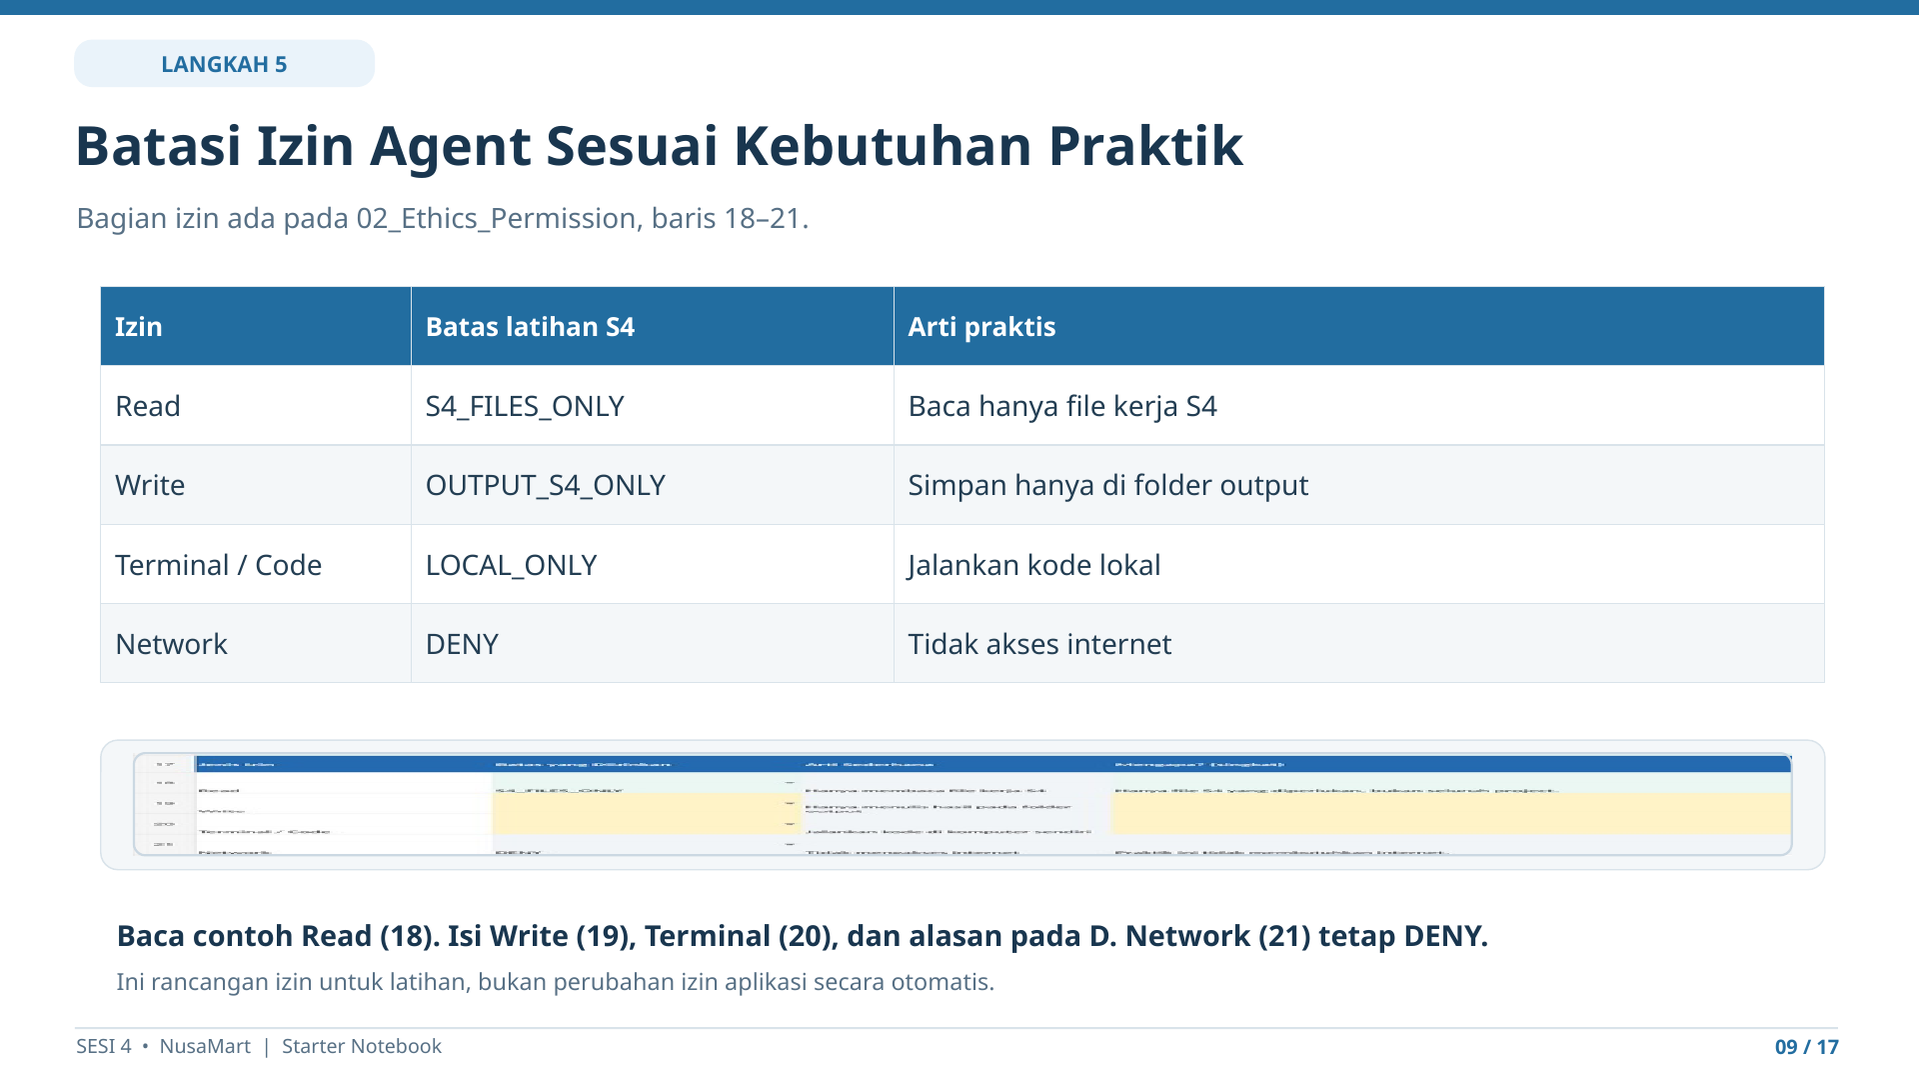

### Langkah 6 — Samakan pilihan Excel dengan Section 5, lalu cek Review Gate

**Mengapa perlu dua file?** Excel menyimpan **pilihan dan alasanmu**; Notebook menggunakan kode pilihan itu untuk menjalankan perlindungan. **Mengisi Excel tidak otomatis mengubah Notebook.**

1. Buka **Section 5**. Pada cell kode bertanda **🟡 EDIT**, cari bagian `HANDLING_PLAN`.
2. Field `customer_id` (**`RESTRICT` + `KEEP`**) dan `customer_name` (**`DO_NOT_SHARE` + `DROP`**) sudah dicontohkan di kode; samakan ke Excel pada baris 6 dan 7.
3. Untuk enam field dengan nilai `TODO`, salin **kode keputusan kolom B** Excel ke `handling` dan **kode teknik kolom C** ke `technique`. Contoh email: `'handling': 'PROTECT', 'technique': 'MASK_EMAIL'`.
4. Pada bagian `AGENT_PERMISSION_PLAN`, isi `read_scope` dari **B18**, `write_scope` dari **B19**, `terminal` dari **B20**; biarkan `network` = `DENY` seperti **B21**.
5. **Ubah hanya teks `TODO`**, bukan nama field, tanda petik, titik dua, atau koma.
6. Klik ▶ pada cell keputusan, lalu klik ▶ pada code cell **Review Gate** sesudahnya.

🔵 **CHECK:** harus muncul `REVIEW GATE: PASS`. Jika `NEEDS INPUT / REVISION`, lihat pesan yang menyebut field atau izin, periksa kembali **Excel B6:D13 dan B18:D21**, lalu ulangi Section 5. Jangan lanjut ke Section 6 sebelum PASS.

📝 **RECORD:** keputusan tetap ada pada `02_Ethics_Permission!B6:D13` dan izin pada **B18:D21**. Kolom E hanya cek awal Excel; **Review Gate harus dijalankan di Notebook**.


#### **Panduan Visual — Langkah 6: Masukkan Keputusan ke Notebook** — EDIT TODO di Section 5 dan baca REVIEW GATE

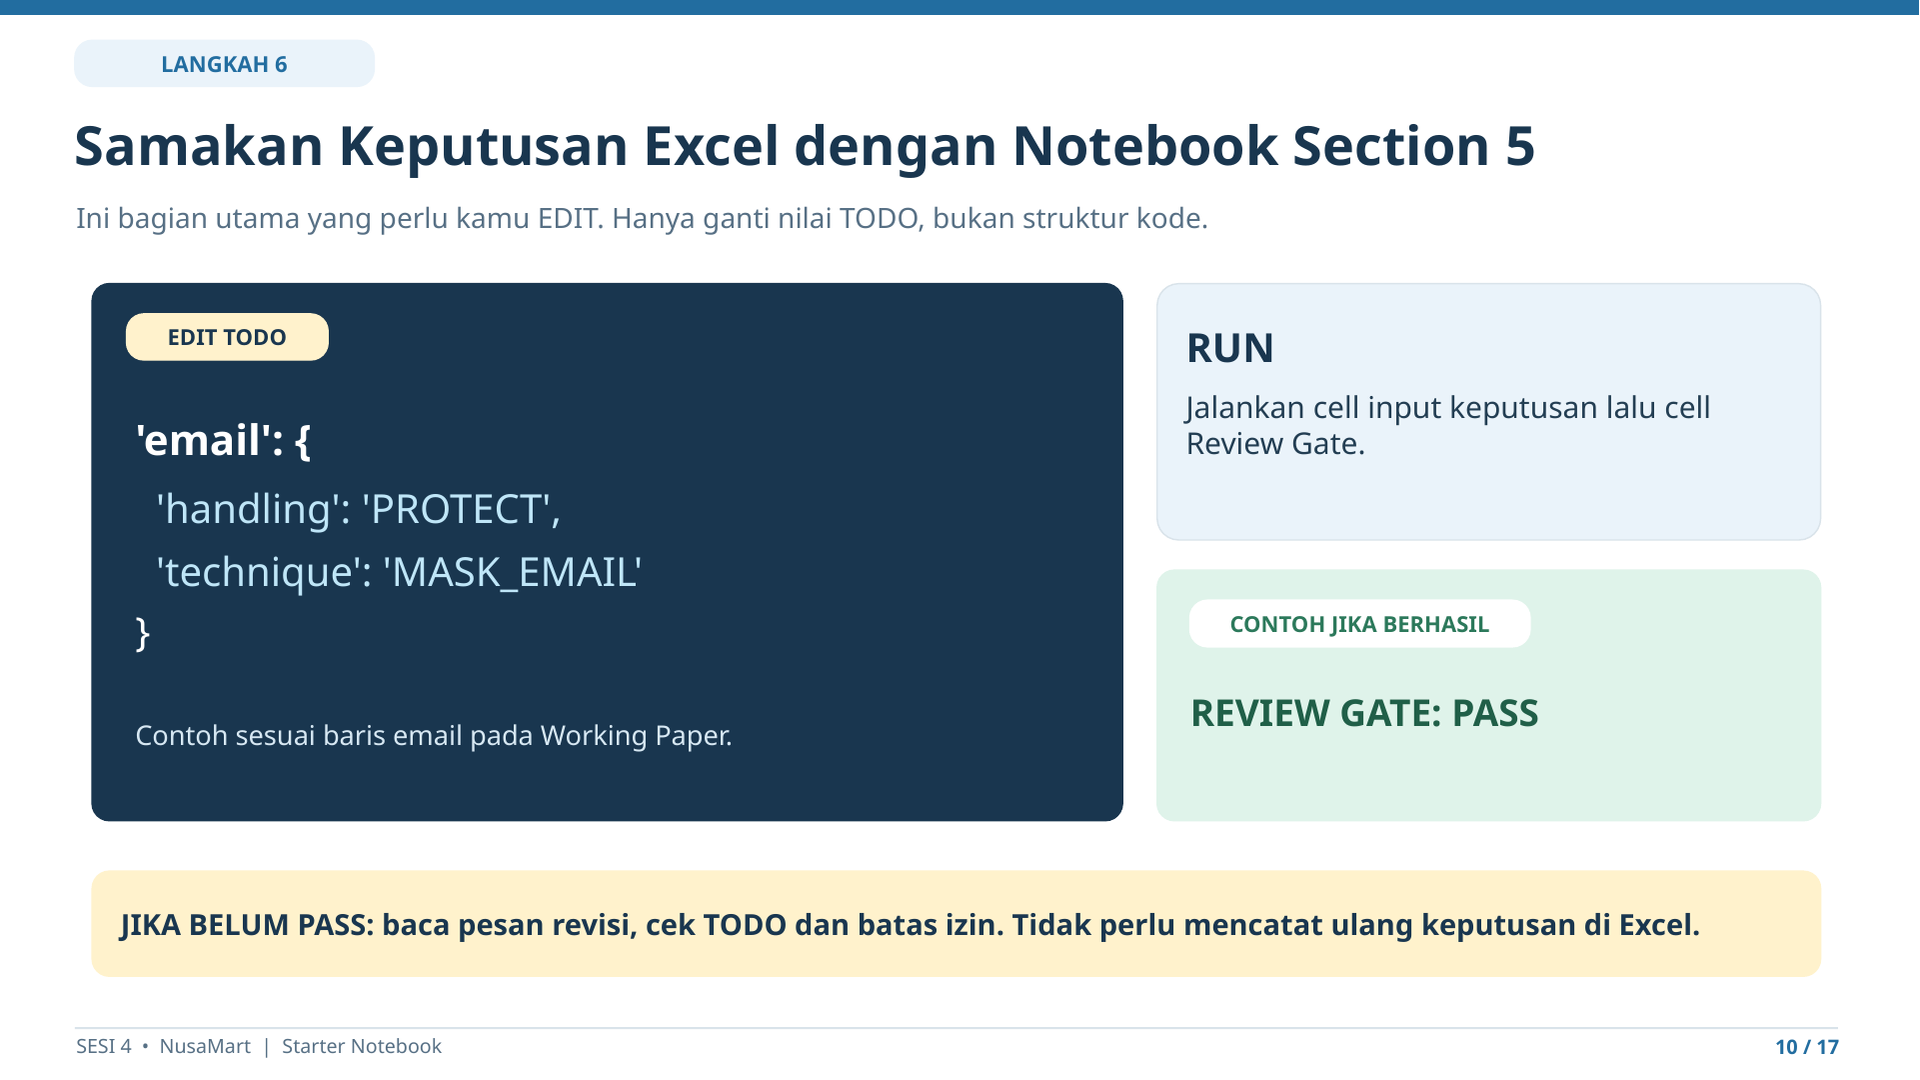


### Section 5 — Masukkan keputusan peserta (satu-satunya bagian utama untuk EDIT)

**Kamu tidak membuat Python dari awal.** Kamu hanya mengganti tulisan `TODO` dengan kode yang sudah dipilih di `02_Ethics_Permission`.

| Field | Keputusan untuk latihan lokal | Alasan |
|---|---|---|
| `customer_id` | `RESTRICT` + `KEEP` — **sudah terisi dalam kode** | Kunci untuk menghubungkan data ke S5, tetapi akses dibatasi |
| `customer_name` | `DO_NOT_SHARE` + `DROP` — **sudah terisi dalam kode** | Nama tidak diperlukan untuk analisis kota dan segmen |
| `city` | `PROTECT` + `GENERALIZE_RARE` | Kota diperlukan; kategori jarang dapat digabung |
| `customer_segment` | `PROTECT` + `GENERALIZE_RARE` | Segmen diperlukan; kategori jarang dapat digabung |
| `join_date` | `PROTECT` + `DATE_TO_QUARTER` | Tidak memerlukan tanggal rinci |
| `email` | `PROTECT` + `MASK_EMAIL` | Demonstrasi masking lokal, bukan untuk berbagi email asli |
| `phone` | `PROTECT` + `MASK_PHONE` | Demonstrasi masking lokal |
| `customer_status` | `ALLOW` + `KEEP` | Status tetap dibutuhkan untuk analisis |

**Tabel di atas memberi contoh keputusan yang konsisten untuk kasus kelas.** Pelajari alasannya; jangan sekadar menyalin jika belum paham. Jika memilih variasi lain, keputusan harus tetap memenuhi aturan Review Gate dan tujuan analisis.

**Izin untuk latihan lokal:** `read_scope = 'S4_FILES_ONLY'`, `write_scope = 'OUTPUT_S4_ONLY'`, `terminal = 'LOCAL_ONLY'`, `network = 'DENY'`. Pada Excel nilainya berada di B18, B19, B20, B21.

🟡 **EDIT:** ganti `TODO` saja, lalu ▶ RUN. **Jangan EDIT fungsi pada Section lainnya.**


In [6]:
# 🟡 EDIT: UBAH HANYA NILAI "TODO". Jangan ganti nama field atau struktur kurung.
HANDLING_PLAN = {
    # DUA CONTOH tersedia. customer_id dijaga untuk join S5; nama tidak diperlukan untuk analisis ini.
    'customer_id':      {'handling': 'RESTRICT', 'technique': 'KEEP'},
    'customer_name':    {'handling': 'DO_NOT_SHARE', 'technique': 'DROP'},
    # ISI sesuai keputusan Praktik 2 (Working Paper):
    'city':             {'handling': 'PROTECT', 'technique': 'GENERALIZE_RARE'},
    'customer_segment': {'handling': 'PROTECT', 'technique': 'GENERALIZE_RARE'},
    'join_date':        {'handling': 'PROTECT', 'technique': 'DATE_TO_QUARTER'},
    'email':            {'handling': 'PROTECT', 'technique': 'MASK_EMAIL'},
    'phone':            {'handling': 'PROTECT', 'technique': 'MASK_PHONE'},
    'customer_status':  {'handling': 'ALLOW', 'technique': 'KEEP'},
}

# 🟡 EDIT: pilih izin minimum, masih pada cell yang sama.
AGENT_PERMISSION_PLAN = {
    'read_scope': 'S4_FILES_ONLY',   # INPUT_ONLY | S4_FILES_ONLY | PROJECT_ALL
    'write_scope': 'OUTPUT_S4_ONLY',  # NONE | OUTPUT_S4_ONLY | PROJECT_ALL
    'terminal': 'LOCAL_ONLY',     # DENY | LOCAL_ONLY | FULL
    'network': 'DENY',     # contoh sudah diisi: S4 tidak perlu internet
}

#### Sesudah RUN cell input Section 5 — Mengapa belum ada status PASS?

- 🔵 **CHECK — Artinya:** Cell ini hanya **menyimpan pilihan yang kamu ketik** dalam `HANDLING_PLAN` dan `AGENT_PERMISSION_PLAN`. **Tidak ada pesan PASS di langkah input adalah hal yang normal**.
- 🟡 **EDIT:** cocokkan satu per satu dengan `02_Ethics_Permission` (keputusan **B6:D13**, izin **B18:D21**). Dua field contoh `customer_id` dan `customer_name` sudah terisi di kode; contoh email sudah terisi di Excel tetapi **masih harus kamu masukkan pada kode**.
- **Jika muncul kesalahan sintaks:** pastikan yang diubah hanya teks `TODO` di dalam tanda kutip. Periksa tanda kutip, koma, dan kurung; jalankan ulang cell.
- 📝 **RECORD:** tidak perlu menulis hasil baru pada Excel. Keputusan sudah berada di Praktik 2. Sekarang RUN **Review Gate** pada cell berikutnya.


### Section 5 — Review Gate: apakah keputusan dapat dilanjutkan?

**Apa yang dilakukan kode?** Memeriksa apakah semua `TODO` telah diisi, teknik sesuai field, informasi penting untuk analisis tidak hilang, dan izin Agent tidak terlalu luas untuk latihan S4.

🟢 **RUN** code cell Review Gate di bawah **setelah** cell keputusan di atas.

🔵 **CHECK:** `REVIEW GATE: PASS` = boleh lanjut. `REVIEW GATE: NEEDS INPUT / REVISION` = ada keputusan yang perlu diperbaiki; **jangan lanjut Section 6**. Periksa field yang disebut, cocokkan dengan Excel, EDIT nilai pada Section 5, RUN ulang input dan Review Gate.

📝 **RECORD:** tidak perlu menambah isian. `SIAP DICEK` atau `READY` di Excel belum berarti `REVIEW GATE: PASS`. Keputusan teknis tetap harus diuji melalui cell Review Gate di bawah.


In [7]:
# 🟢 RUN (JANGAN EDIT) — Review Gate membantu memeriksa apakah keputusan sudah aman untuk case ini.
ALLOWED_HANDLING = {'ALLOW','PROTECT','RESTRICT','DO_NOT_SHARE'}
ALLOWED_TECHNIQUES = {'KEEP','DROP','REDACT','MASK_TEXT','MASK_EMAIL','MASK_PHONE','SHA256','DATE_TO_QUARTER','GENERALIZE_RARE'}
REQUIRED_ANALYTIC_COLUMNS = {'city','customer_segment','customer_status'}
STRONG_RAW_REMOVAL = {'DROP','REDACT','MASK_TEXT','MASK_EMAIL','MASK_PHONE','SHA256','DATE_TO_QUARTER'}
FIELD_TECHNIQUES = {
    'customer_id': {'KEEP'},
    'customer_name': {'DROP','REDACT'},
    'email': {'DROP','REDACT','MASK_EMAIL','SHA256'},
    'phone': {'DROP','REDACT','MASK_PHONE','SHA256'},
    'city': {'KEEP','GENERALIZE_RARE'},
    'customer_segment': {'KEEP','GENERALIZE_RARE'},
    'join_date': {'KEEP','DATE_TO_QUARTER','DROP'},
    'customer_status': {'KEEP'},
}

def normalize_plan(plan):
    normalized = {}
    for field,cfg in plan.items():
        handling = str(cfg.get('handling','')).strip().upper()
        technique = str(cfg.get('technique','')).strip().upper()
        normalized[field] = {'handling':handling, 'technique':technique,
            # YES = nilai asli tidak boleh muncul lagi di protected output.
            'remove_raw': 'YES' if technique in STRONG_RAW_REMOVAL else 'NO'}
    return normalized

def review_handling_plan(plan):
    plan = normalize_plan(plan)
    issues=[]; warnings=[]
    for field in EXPECTED_COLUMNS:
        if field not in plan:
            issues.append(f'{field}: belum ada di HANDLING_PLAN.')
            continue
        h=plan[field]['handling'];t=plan[field]['technique']
        if h not in ALLOWED_HANDLING: issues.append(f'{field}: handling {h!r} tidak valid / masih TODO.')
        if t not in ALLOWED_TECHNIQUES: issues.append(f'{field}: technique {t!r} tidak valid / masih TODO.')
        if t not in FIELD_TECHNIQUES[field]: issues.append(f'{field}: teknik {t} tidak sesuai jenis field. Pilih: {sorted(FIELD_TECHNIQUES[field])}.')
        if h=='ALLOW' and t!='KEEP': issues.append(f'{field}: ALLOW hanya untuk nilai yang tidak ditransform (KEEP).')
        if h=='PROTECT' and t=='KEEP': issues.append(f'{field}: PROTECT memerlukan teknik perlindungan, bukan KEEP.')
        if h=='DO_NOT_SHARE' and t not in {'DROP','REDACT'}: issues.append(f'{field}: DO_NOT_SHARE harus DROP/REDACT pada output case ini.')
        if h in {'ALLOW','RESTRICT'} and t not in {'KEEP','GENERALIZE_RARE'}:
            issues.append(f'{field}: {h} tidak sesuai teknik {t}; gunakan PROTECT bila mentransform nilai.')
    for extra in set(plan) - set(EXPECTED_COLUMNS): issues.append(f'Field tambahan tidak dikenal: {extra}.')
    cid=plan.get('customer_id',{})
    if cid.get('handling')!='RESTRICT' or cid.get('technique')!='KEEP':
        issues.append('customer_id wajib RESTRICT + KEEP, key dijaga untuk S5 tetapi aksesnya terbatas.')
    name=plan.get('customer_name',{})
    if name.get('handling')!='DO_NOT_SHARE' or name.get('technique')!='DROP':
        issues.append('customer_name tidak diperlukan: pilih DO_NOT_SHARE + DROP.')
    for field in ('email','phone'):
        cfg=plan.get(field,{})
        if cfg.get('technique')=='KEEP' or cfg.get('handling')=='ALLOW':
            issues.append(f'{field}: jangan mempertahankan/membolehkan PII mentah.')
        if cfg.get('technique') in {'MASK_EMAIL','MASK_PHONE','SHA256'} and cfg.get('handling') not in {'PROTECT','RESTRICT'}:
            issues.append(f'{field}: derivative masking/hash harus PROTECT atau RESTRICT sesuai purpose.')
    for field in REQUIRED_ANALYTIC_COLUMNS:
        if plan.get(field,{}).get('technique')=='DROP': issues.append(f'{field}: jangan DROP kolom analitik utama.')
    if plan.get('join_date',{}).get('technique')=='KEEP':
        warnings.append('join_date dibiarkan rinci; review kembali risiko kombinasi tanggal, kota, segmen.')
    if plan.get('city',{}).get('technique')=='KEEP':
        warnings.append('city tidak digeneralisasi; analisis linkability harus dicatat di Working Paper.')
    return plan,issues,warnings

def review_permissions(permission_plan):
    p={k:str(v).strip().upper() for k,v in permission_plan.items()}
    valid={'read_scope':{'INPUT_ONLY','S4_FILES_ONLY','PROJECT_ALL'},
           'write_scope':{'NONE','OUTPUT_S4_ONLY','PROJECT_ALL'},
           'terminal':{'DENY','LOCAL_ONLY','FULL'},'network':{'DENY','ALLOW'}}
    issues=[]
    for key,allowed in valid.items():
        if p.get(key) not in allowed: issues.append(f'{key}: nilai {p.get(key)!r} tidak valid / masih TODO.')
    if p.get('read_scope')=='PROJECT_ALL':issues.append('read_scope terlalu luas untuk S4.')
    if p.get('write_scope')!='OUTPUT_S4_ONLY':issues.append('write_scope pilih OUTPUT_S4_ONLY untuk menyimpan evidence.')
    if p.get('terminal')!='LOCAL_ONLY':issues.append('terminal pilih LOCAL_ONLY karena Notebook menjalankan kode lokal.')
    if p.get('network')!='DENY':issues.append('network S4 harus DENY (tidak memerlukan internet).')
    return p,issues

normalized_plan,handling_issues,handling_warnings=review_handling_plan(HANDLING_PLAN)
normalized_permissions,permission_issues=review_permissions(AGENT_PERMISSION_PLAN)
review_issues=handling_issues+permission_issues
review_gate_pass=not review_issues
if handling_warnings:
    print('CATATAN REVIEW (bukan error, pertimbangkan risikonya sebelum lanjut):')
    for line in handling_warnings:print(' -',line)
if review_gate_pass:
    print('REVIEW GATE: PASS')
    print('NEXT: Section 6 (RUN fungsi; jangan edit).')
else:
    print('REVIEW GATE: NEEDS INPUT / REVISION')
    for line in review_issues: print(' -',line)
    print('AKSI: perbaiki hanya cell HANDLING_PLAN / AGENT_PERMISSION_PLAN di atas; RUN ulang Section 5 lalu lanjut.')

REVIEW GATE: PASS
NEXT: Section 6 (RUN fungsi; jangan edit).


#### Sesudah RUN Review Gate — Apakah keputusan dapat dilanjutkan?

**Contoh output jika berhasil:** `REVIEW GATE: PASS`.

- 🔵 **CHECK — Artinya:** Notebook memeriksa apakah keputusan untuk delapan field dan empat batas izin memenuhi aturan latihan. Ibarat aturan petugas, siapa yang boleh mengakses informasi apa sudah diperiksa sebelum pekerjaan dilanjutkan.
- **Jika `REVIEW GATE: NEEDS INPUT / REVISION`:** baca daftar masalah yang dicetak. Cocokkan **kolom E `Hasil Cek`** pada `02_Ethics_Permission` (bisa `BELUM LENGKAP`, `PERIKSA PILIHAN`, atau `SIAP DICEK`), perbaiki pilihan dan `TODO` pada Section 5, lalu RUN ulang **dua cell Section 5** secara berurutan.
- **Jika muncul `CATATAN REVIEW`:** ini **peringatan untuk dipertimbangkan**, tidak selalu berarti proses gagal. Tinjau alasan risiko, misalnya jika kota tidak digeneralisasi. Konsultasikan dengan trainer jika dampaknya belum dipahami.
- 📝 **RECORD:** **CHECK SAJA**. `SIAP DICEK` di Excel **bukan** `REVIEW GATE: PASS`; keputusan tetap tercatat pada Praktik 2. Baru lanjut Section 6 jika Review Gate PASS.


---
## PRAKTIK 3 — Lindungi dan Periksa Data Pelanggan
### Studi kasus: apakah data hasil perlindungan masih aman dan berguna?

NusaMart telah menentukan cara menangani delapan kolom. Sekarang kamu akan menjalankan teknik tersebut pada **salinan** data, lalu memeriksa apakah:

1. **File bersih S3 tetap utuh** (penting untuk kelanjutan S5).
2. **Nilai mentah yang ditargetkan tidak ditemukan** pada pemeriksaan perlindungan.
3. **Jumlah baris dan `customer_id` tidak rusak**.
4. **Informasi kota, segmen, dan status pelanggan masih berguna** untuk analisis.

**Beberapa teknik yang muncul:** `DROP` = tidak membawa kolom ke output; `MASK_EMAIL` / `MASK_PHONE` = menyamarkan sebagian karakter; `DATE_TO_QUARTER` = mengurangi rincian tanggal; `GENERALIZE_RARE` = menggabungkan kategori jarang; `SHA256` = membuat hash yang konsisten. Semua punya batasan; **masking/hash tidak otomatis membuat data anonim**.

📝 **Output resmi Praktik 3:** Notebook dengan skrip perlindungan yang telah diuji. Sheet `03_Verification_Evidence` adalah **catatan bukti pendukung**, bukan output resmi keempat.

**Analogi singkat:** kamu sudah membuat aturan bagian dokumen yang perlu disamarkan. Sekarang aturan itu diterapkan pada **salinan** dan diperiksa ulang, bukan langsung membagikan hasilnya.



#### **Panduan Visual — Pahami Dulu: Bagaimana Data Pribadi Bisa Dilindungi?** — Contoh teknik perlindungan — masking, hash, drop, generalisasi

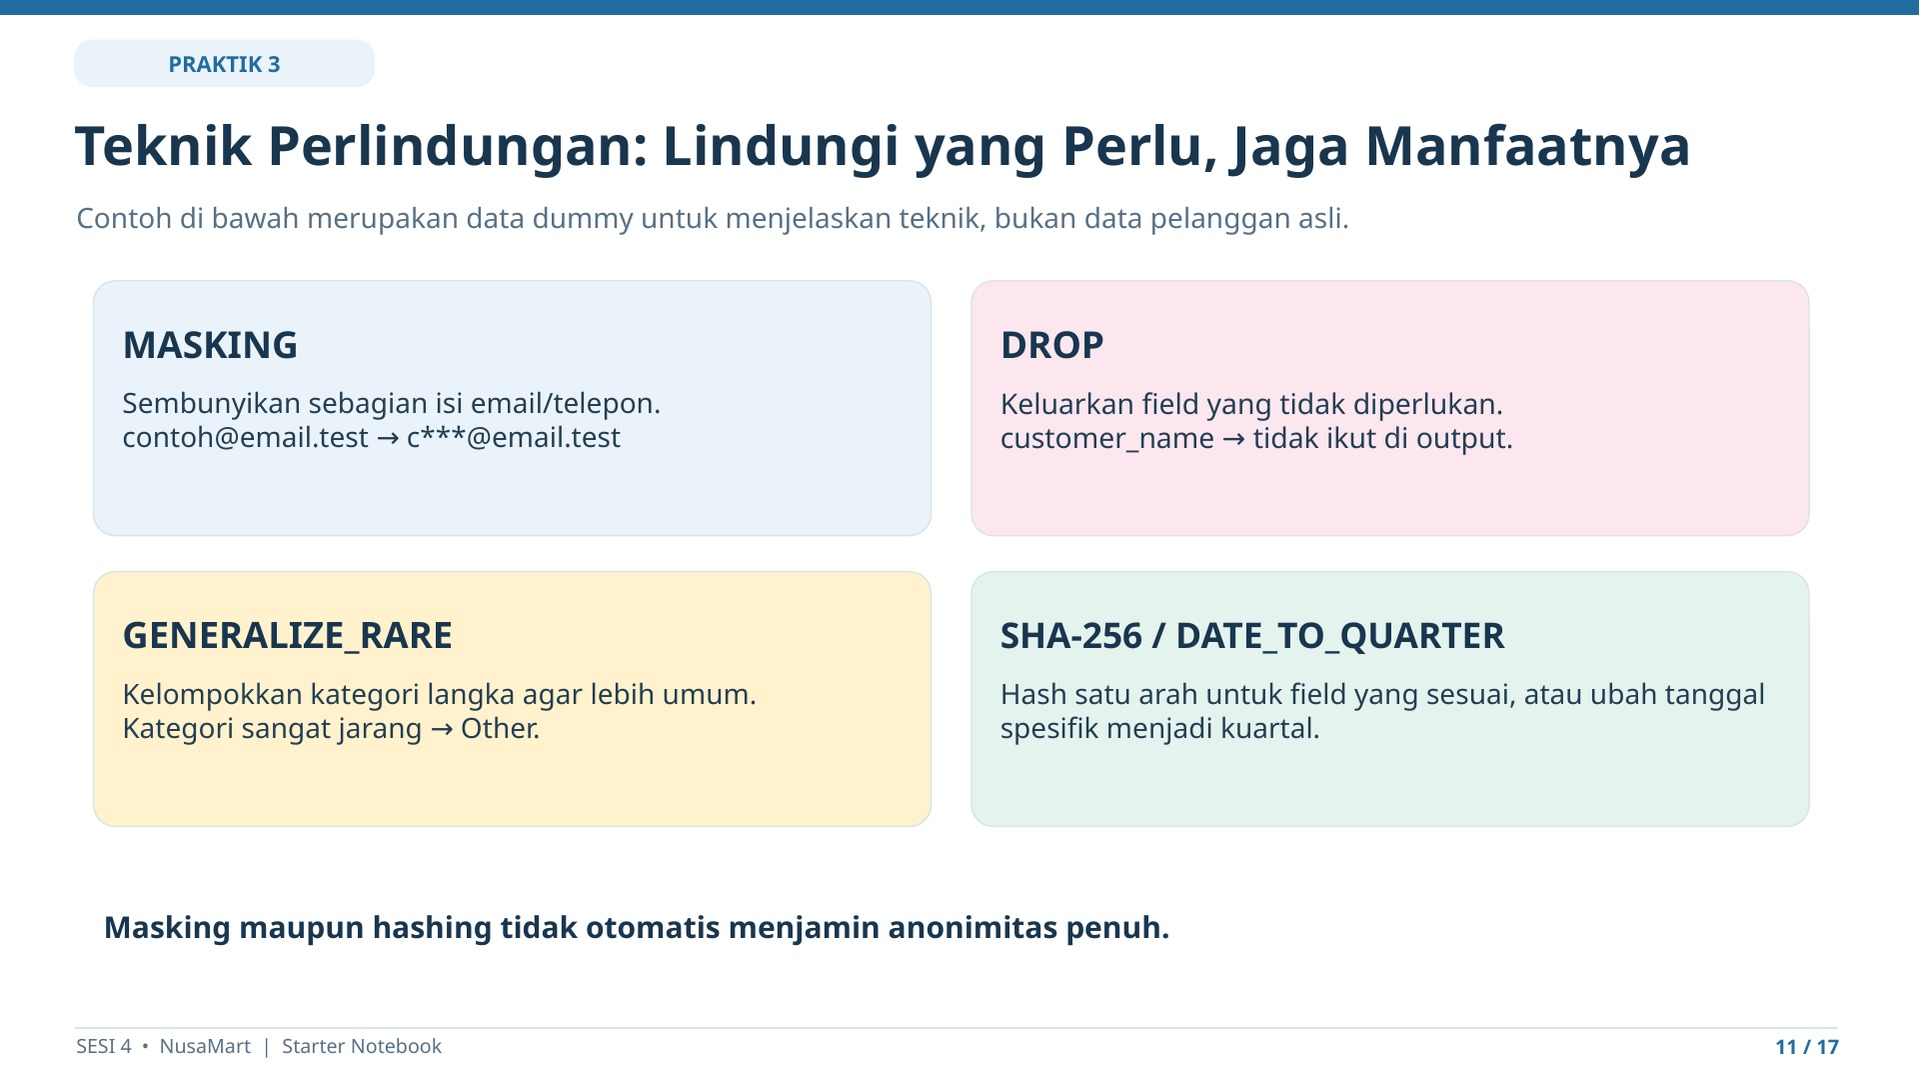


### Langkah 7 — Jalankan perlindungan sesuai keputusan

1. Pastikan Section 5 menunjukkan **`REVIEW GATE: PASS`**.
2. Jalankan **Section 6** (menyiapkan fungsi perlindungan). Kamu **tidak perlu menulis fungsi** Python sendiri.
3. Jalankan **Section 7** (menerapkan keputusan dari Section 5 pada salinan data).
4. Baca tabel hasil: `field` = informasi yang diproses; `technique` = teknik yang dipakai; `status` = dipertahankan, diubah, atau dikeluarkan.
5. Bandingkan daftar teknik dengan `02_Ethics_Permission` kolom B–C.

🔵 **CHECK:** `PROTECTION FUNCTIONS: READY` dan `PROTECTION EXECUTION: PASS`.

📝 **RECORD:** **belum pilih PASS pada VT-05** sampai membaca juga ringkasan Section 8. Hasil Section 7–8 dicatat bersama pada `03_Verification_Evidence!D10:E10`.


#### **Panduan Visual — Langkah 7: Jalankan Perlindungan Data** — RUN Section 6–7, baca status protection

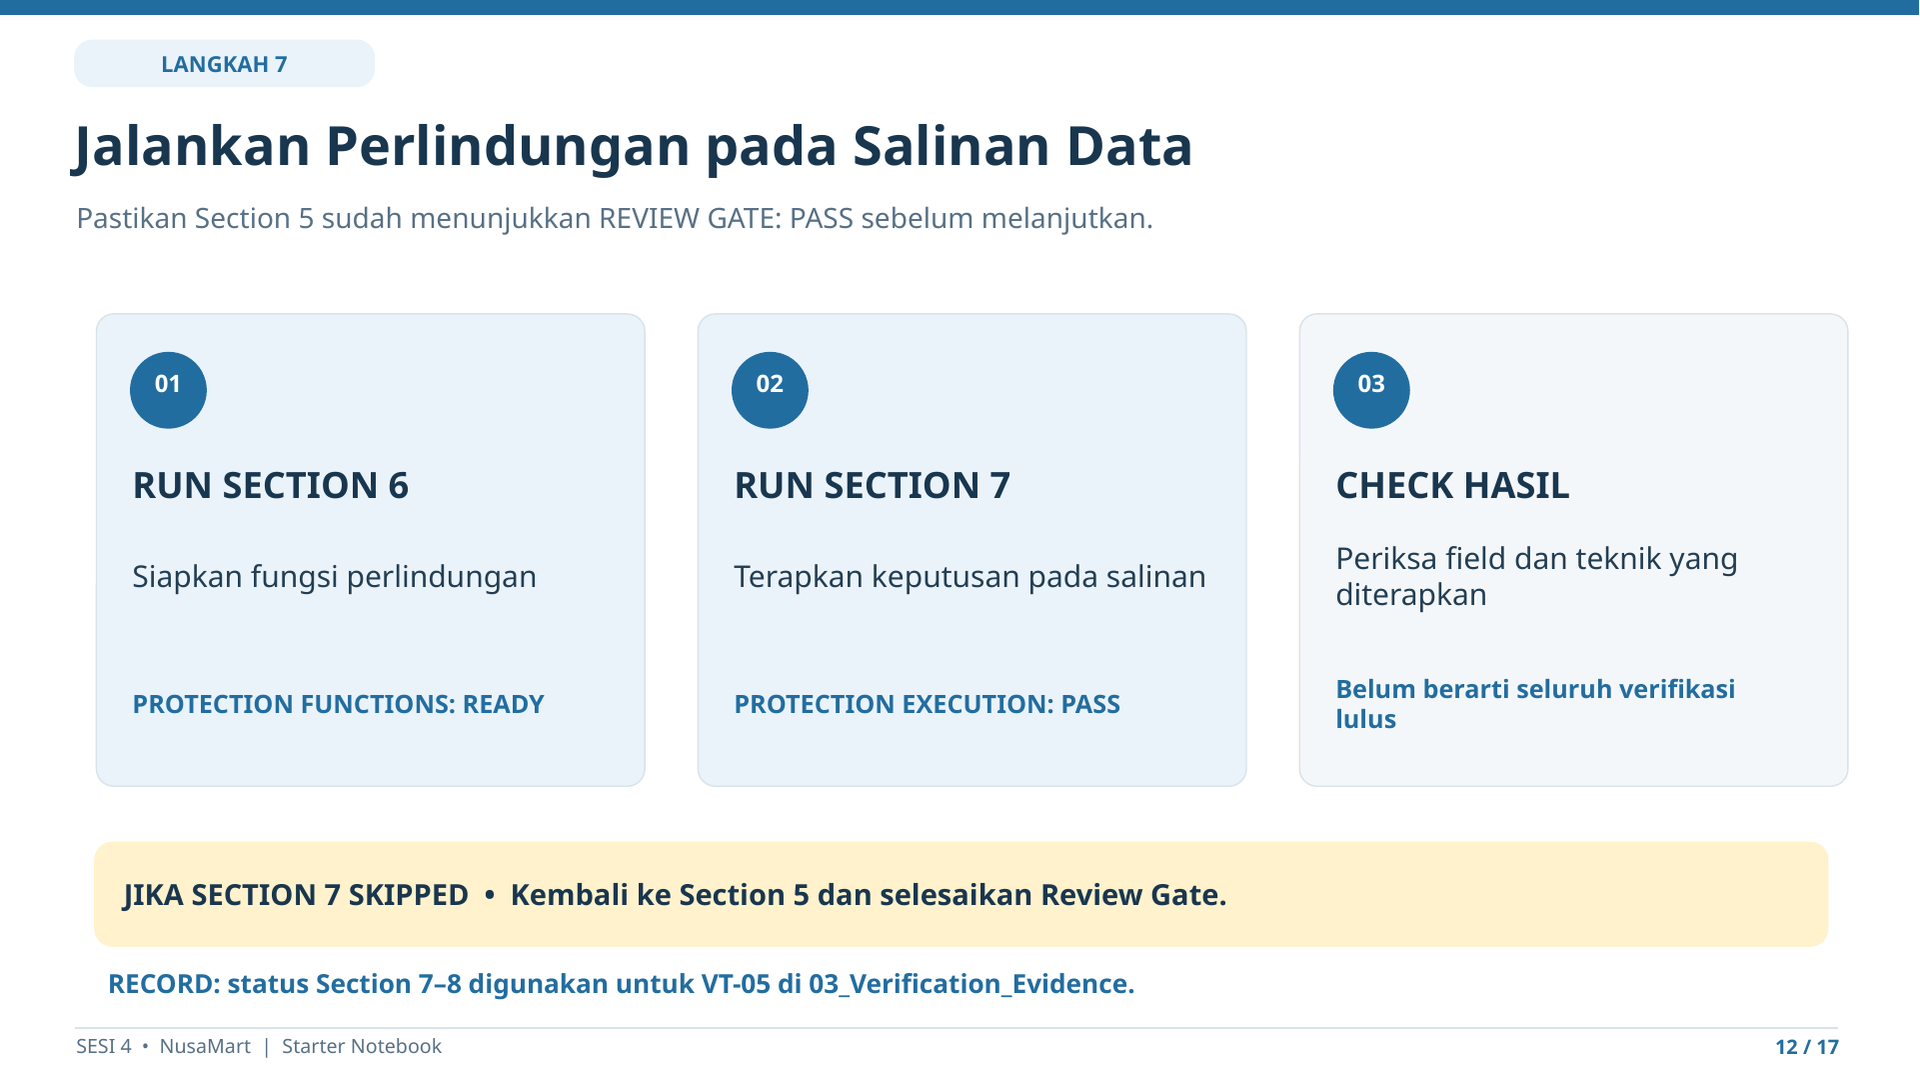


### Section 6 — Siapkan fungsi perlindungan (cukup RUN)

**Apa yang dilakukan kode?** Menyiapkan beberapa cara mengolah data seperti masking dan hash; **belum** menerapkannya pada data pelanggan.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `PROTECTION FUNCTIONS: READY`.

📝 **RECORD:** **belum ada isian Excel**. Lanjut Section 7 untuk menerapkan perlindungan.


In [8]:
def _is_missing(value):
    return pd.isna(value)

def redact(value):
    if _is_missing(value):
        return value
    return "[REDACTED]"

def mask_text(value):
    if _is_missing(value):
        return value
    text = str(value)
    if len(text) <= 1:
        return "*"
    return text[0] + ("*" * max(3, len(text) - 1))

def mask_email(value):
    if _is_missing(value):
        return value
    text = str(value)
    if "@" not in text:
        return mask_text(text)
    local, domain = text.rsplit("@", 1)
    if len(local) <= 2:
        masked_local = local[0] + "***" if local else "***"
    else:
        masked_local = local[0] + "***" + local[-2:]
    return f"{masked_local}@{domain}"

def mask_phone(value):
    if _is_missing(value):
        return value
    text = str(value)
    digits = re.sub(r"\D", "", text)
    if len(digits) <= 8:
        return "*" * len(digits)
    middle_len = len(digits) - 8
    return digits[:4] + ("*" * middle_len) + digits[-4:]

def sha256_pseudonymize(value, salt="nusamart-s4-training"):
    if _is_missing(value):
        return value
    payload = f"{salt}|{str(value).strip()}".encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

def date_to_quarter(value):
    if _is_missing(value):
        return value
    parsed = pd.to_datetime(value, errors="coerce")
    if pd.isna(parsed):
        return "UNKNOWN_DATE"
    return f"{parsed.year}-Q{parsed.quarter}"

def generalize_rare(series, min_count=5, other_label="OTHER"):
    counts = series.value_counts(dropna=False)
    rare_values = set(counts[counts < min_count].index.tolist())
    return series.apply(lambda x: other_label if x in rare_values and not pd.isna(x) else x)

TECHNIQUE_FUNCTIONS = {
    "REDACT": redact,
    "MASK_TEXT": mask_text,
    "MASK_EMAIL": mask_email,
    "MASK_PHONE": mask_phone,
    "SHA256": sha256_pseudonymize,
    "DATE_TO_QUARTER": date_to_quarter,
}

print("PROTECTION FUNCTIONS: READY")
print("Available:", sorted(ALLOWED_TECHNIQUES))

PROTECTION FUNCTIONS: READY
Available: ['DATE_TO_QUARTER', 'DROP', 'GENERALIZE_RARE', 'KEEP', 'MASK_EMAIL', 'MASK_PHONE', 'MASK_TEXT', 'REDACT', 'SHA256']


#### Sesudah RUN Section 6 — Teknik sudah disiapkan, belum diterapkan

**Contoh output:** `PROTECTION FUNCTIONS: READY`.

- 🔵 **CHECK — Artinya:** Notebook sudah menyiapkan *alat pengolahan* seperti masking, penghapusan kolom, generalisasi, dan SHA-256. Bayangkan alat penyensor dokumen sudah siap di meja, tetapi belum digunakan pada salinannya.
- **Jika gagal:** pastikan cell Section 6 dijalankan utuh, bukan sebagian teks kode. Periksa pesan Python sebelum mencoba lagi.
- 📝 **RECORD:** **CHECK SAJA**; belum mengisi tes verifikasi. Lanjut Section 7.


### Section 7 — Terapkan keputusan pada salinan data

**Apa yang dilakukan kode?** Menjalankan teknik yang kamu pilih di `HANDLING_PLAN` dan menampilkan daftar tindakan pada delapan field. File sumber S3 tidak ditimpa.

🟢 **RUN** setelah Review Gate PASS, tanpa EDIT.

🔵 **CHECK:** `PROTECTION EXECUTION: PASS` dan daftar `field / technique / status`. Jika `SECTION 7 SKIPPED`, kembali ke Review Gate pada Section 5.

📝 **RECORD:** tunggu hasil Section 8 juga, lalu isi **VT-05 / `03_Verification_Evidence!D10:E10`**. Status harus sesuai hasil aktual.


In [9]:
protected = None
applied_actions = []

if not review_gate_pass:
    print("SECTION 7 SKIPPED — REVIEW GATE belum PASS.")
else:
    protected = working.copy(deep=True)

    for field in EXPECTED_COLUMNS:
        technique = normalized_plan[field]["technique"]

        if technique == "KEEP":
            applied_actions.append((field, technique, "kept"))
            continue

        if technique == "DROP":
            protected = protected.drop(columns=[field])
            applied_actions.append((field, technique, "dropped"))
            continue

        if technique == "GENERALIZE_RARE":
            protected[field] = generalize_rare(protected[field])
            applied_actions.append((field, technique, "transformed"))
            continue

        transform = TECHNIQUE_FUNCTIONS[technique]
        protected[field] = protected[field].apply(transform)
        applied_actions.append((field, technique, "transformed"))

    print("PROTECTION EXECUTION: PASS")
    display(pd.DataFrame(applied_actions, columns=["field", "technique", "status"]))

PROTECTION EXECUTION: PASS


,field,technique,status
0,customer_id,KEEP,kept
1,customer_name,DROP,dropped
2,city,GENERALIZE_RARE,transformed
3,customer_segment,GENERALIZE_RARE,transformed
4,join_date,DATE_TO_QUARTER,transformed
5,email,MASK_EMAIL,transformed
6,phone,MASK_PHONE,transformed
7,customer_status,KEEP,kept


#### Sesudah RUN Section 7 — Perlindungan sudah diterapkan?

**Contoh output jika berhasil:** `PROTECTION EXECUTION: PASS` serta tabel `field`, `technique`, `status`.

- 🔵 **CHECK — Artinya:** Teknik yang dipilih pada `HANDLING_PLAN` sudah dijalankan pada **salinan** data. `field` = nama informasi, `technique` = cara yang diterapkan, `status` = apakah kolom diubah atau dikeluarkan. **Ini belum membuktikan bahwa semua pemeriksaan keamanan berhasil.**
- **Jika `SECTION 7 SKIPPED`:** Review Gate pada Section 5 belum lulus. Perbaiki keputusan, RUN ulang Section 5, kemudian Section 7. Jangan menulis PASS sebelum RUN.
- 📝 **RECORD:** hasil Section 7 akan dicocokkan dengan ringkasan Section 8 untuk **VT-05 → `03_Verification_Evidence!D10:E10`**. D10 berisi bukti ringkas aktual, E10 status yang benar; F10 untuk masalah.


### Langkah 8 — Baca ringkasan hasil perlindungan

1. RUN **Section 8** untuk melihat berapa baris berubah akibat tiap teknik. Ringkasan ini tidak menampilkan email/telepon/nama mentah.
2. Baca `field` (nama informasi), `technique` (cara perlindungan), `rows_changed` (berapa baris berubah), `raw_removed` (apakah teknik ditujukan untuk menghilangkan bentuk mentah).
3. Bandingkan teknik di Section 7–8 dengan `02_Ethics_Permission`. Jangan menyamakan `raw_removed` dengan jaminan anonimitas.
4. Isi hasil gabungan Section 7–8 pada `03_Verification_Evidence` **VT-05 (D10:E10)**. Jika berbeda dari keputusan, tulis masalahnya pada **F10**.
5. RUN **Section 9** untuk melihat rencana lokasi penyimpanan. `PENDING VERIFICATION` **bukan FAIL**: file final memang belum boleh disimpan sebelum semua tes selesai.

🔵 **CHECK:** `PREVIEW CHECK: READY` dan `PROTECTED OUTPUT: PENDING VERIFICATION`.


#### **Panduan Visual — Langkah 8: Periksa Perubahan Data** — Baca perubahan dan status pending verification

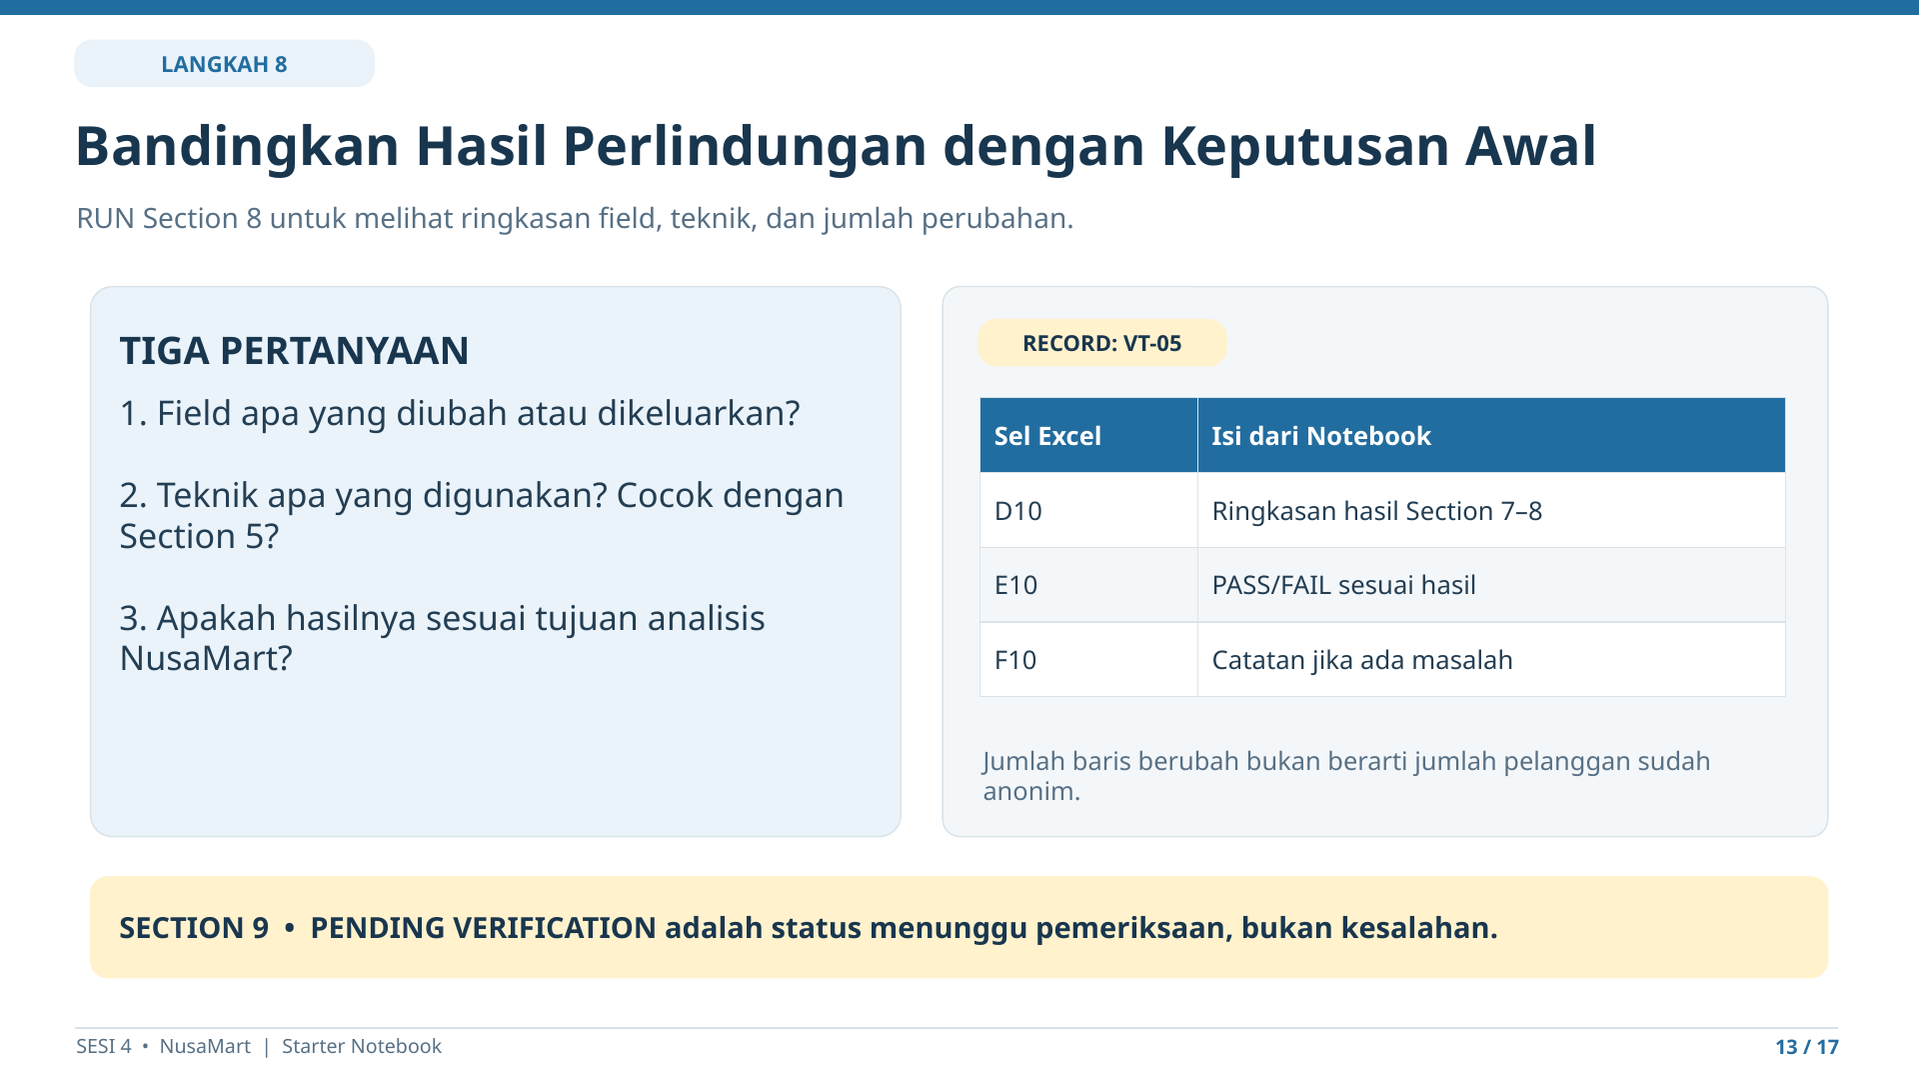


### Section 8 — Ringkasan perubahan sebelum dan sesudah

**Apa yang dilakukan kode?** Menunjukkan teknik dan jumlah perubahan, tanpa mencetak data pribadi mentah.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `PREVIEW CHECK: READY`. Baca tabel bersama output Section 7.

📝 **RECORD:** `03_Verification_Evidence` → **VT-05 (D10 = hasil aktual, E10 = status)**. Jika belum yakin bahwa teknik sesuai rencana, isi **NEEDS REVIEW** dan lihat kembali teknik Section 5 dan minta bantuan trainer jika tidak jelas; jangan memilih PASS secara otomatis.


In [10]:
# 🟢 RUN — cek perbedaan dalam bentuk RINGKAS tanpa menampilkan PII.
before_after_preview=None
if not review_gate_pass:
    print('SECTION 8 SKIPPED — REVIEW GATE belum PASS.')
else:
    rows=[]
    for field in EXPECTED_COLUMNS:
        tech=normalized_plan[field]['technique']
        if tech=='KEEP':continue
        if field not in protected.columns:
            changed=len(customers)
        else:
            orig=customers[field].astype('string').fillna('<MISSING>')
            after=protected[field].astype('string').fillna('<MISSING>')
            changed=int((orig!=after).sum())
        rows.append({'field':field,'technique':tech,'rows_changed':changed,
                     'raw_removed':normalized_plan[field]['remove_raw']})
    before_after_preview=pd.DataFrame(rows)
    display(before_after_preview)
    print('PREVIEW CHECK: READY — hanya summary, tanpa nilai PII asli.')

,field,technique,rows_changed,raw_removed
0,customer_name,DROP,215,YES
1,city,GENERALIZE_RARE,0,NO
2,customer_segment,GENERALIZE_RARE,6,NO
3,join_date,DATE_TO_QUARTER,215,YES
4,email,MASK_EMAIL,215,YES
5,phone,MASK_PHONE,215,YES


PREVIEW CHECK: READY — hanya summary, tanpa nilai PII asli.


#### Sesudah RUN Section 8 — Memahami tabel perubahan dan mengisi VT-05

**Contoh output jika berhasil:** tabel `field`, `technique`, `rows_changed`, `raw_removed` dan teks `PREVIEW CHECK: READY`.

| Tulisan output | Arti sederhana |
|---|---|
| `field` | Kolom yang dikenai teknik perlindungan. |
| `technique` | Teknik yang diterapkan, misalnya `MASK_EMAIL` atau `GENERALIZE_RARE`. |
| `rows_changed` | Jumlah baris yang nilainya berbeda sebelum dan sesudah proses. **Bukan jumlah orang yang dijamin anonim.** |
| `raw_removed` | `YES` jika teknik tergolong meniadakan bentuk mentah untuk field tersebut menurut aturan Notebook, **bukan jaminan anonim**. |

- 🔵 **CHECK — Artinya:** Bandingkan daftar teknik dan perubahan dengan keputusan di Praktik 2. Status `PREVIEW CHECK: READY` berarti ringkasan tersedia, **belum berarti leak check sudah lulus**.
- **Jika `SECTION 8 SKIPPED`:** kembali perbaiki Review Gate Section 5 dan RUN perlindungan lagi.
- 📝 **RECORD:** `03_Verification_Evidence` → **VT-05 / baris 10**. **D10:** tulis hasil aktual Section 7–8 (misalnya `PROTECTION EXECUTION: PASS; teknik sesuai HANDLING_PLAN`, *hanya bila benar demikian*); **E10:** PASS/FAIL/NEEDS REVIEW berdasarkan hasil; **F10:** masalah jika ada. Jangan mengisi VT-01 sebelum menjalankan Section 11.


### Section 9 — Lihat lokasi hasil yang akan disimpan

**Apa yang dilakukan kode?** Menunjukkan rencana file hasil di `outputs/sesi_04/customers_protected_preview.csv`. Section ini **belum menyimpan file**.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `PROTECTED OUTPUT: PENDING VERIFICATION` berarti menunggu semua tes Section 10–13, **bukan error**.

📝 **RECORD:** **tidak perlu mengisi Excel** dari pesan PENDING. Lanjut ke pemeriksaan sumber, PII, ID, dan kegunaan analisis.


In [11]:
# 🟢 RUN — file protected baru disimpan setelah semua check PASS di Section 14.
PROTECTED_OUTPUT_PATH=OUTPUT_DIR/'customers_protected_preview.csv'
protected_output_saved=False
if not review_gate_pass:
    print('SECTION 9 SKIPPED — REVIEW GATE belum PASS.')
else:
    print('PROTECTED OUTPUT: PENDING VERIFICATION')
    print('Lokasi setelah PASS:',PROTECTED_OUTPUT_PATH)
    print('NEXT: Section 10–13, semua harus PASS sebelum file disimpan.')

PROTECTED OUTPUT: PENDING VERIFICATION
Lokasi setelah PASS: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_04\customers_protected_preview.csv
NEXT: Section 10–13, semua harus PASS sebelum file disimpan.


#### Sesudah RUN Section 9 — Mengapa file hasil belum disimpan?

**Contoh output:** `PROTECTED OUTPUT: PENDING VERIFICATION`.

- 🔵 **CHECK — Artinya:** Notebook baru memberi tahu **lokasi yang direncanakan** untuk file hasil. Status *PENDING* artinya **masih menunggu pemeriksaan**, bukan error. Bayangkan salinan dokumen belum boleh dilepas sebelum pemeriksaan selesai.
- **Jika `SECTION 9 SKIPPED`:** periksa Review Gate Section 5. Jangan memindahkan atau membagikan file sumber.
- 📝 **RECORD:** **CHECK SAJA**. Tidak ada tes baru; file protected akan disimpan oleh Section 14 **hanya jika seluruh pemeriksaan wajib lulus**.


### Pahami Dulu — Mengapa hasil perlindungan perlu diperiksa?

**Kasus NusaMart:** menyamarkan email memang dapat mengurangi paparan informasi pribadi. Tetapi jika `city` atau `customer_segment` hilang, tim tidak dapat membuat analisis yang diminta. Karena itu kita memeriksa **perlindungan dan kegunaan data bersama-sama**.

Enam pemeriksaan di `03_Verification_Evidence` mencakup: kebocoran nilai pribadi yang ditargetkan, keutuhan file asli, jumlah pelanggan, keutuhan `customer_id`, kecocokan teknik perlindungan, dan kegunaan informasi analitik.

🔵 **CHECK:** setiap pemeriksaan harus berasal dari RUN yang benar-benar dilakukan. `PASS` pada latihan **bukan jaminan data anonim di semua situasi**.

**Analogi singkat:** setelah dokumen disensor, periksa apakah informasi pribadi yang ditargetkan tidak terlihat lagi **dan** bagian yang diperlukan untuk bekerja tetap terbaca. Hasil tes latihan tetap memiliki keterbatasan.



#### **Panduan Visual — Pahami Dulu: Mengapa Data Harus Diperiksa Lagi?** — Empat alasan verifikasi: source, leak, key, utility

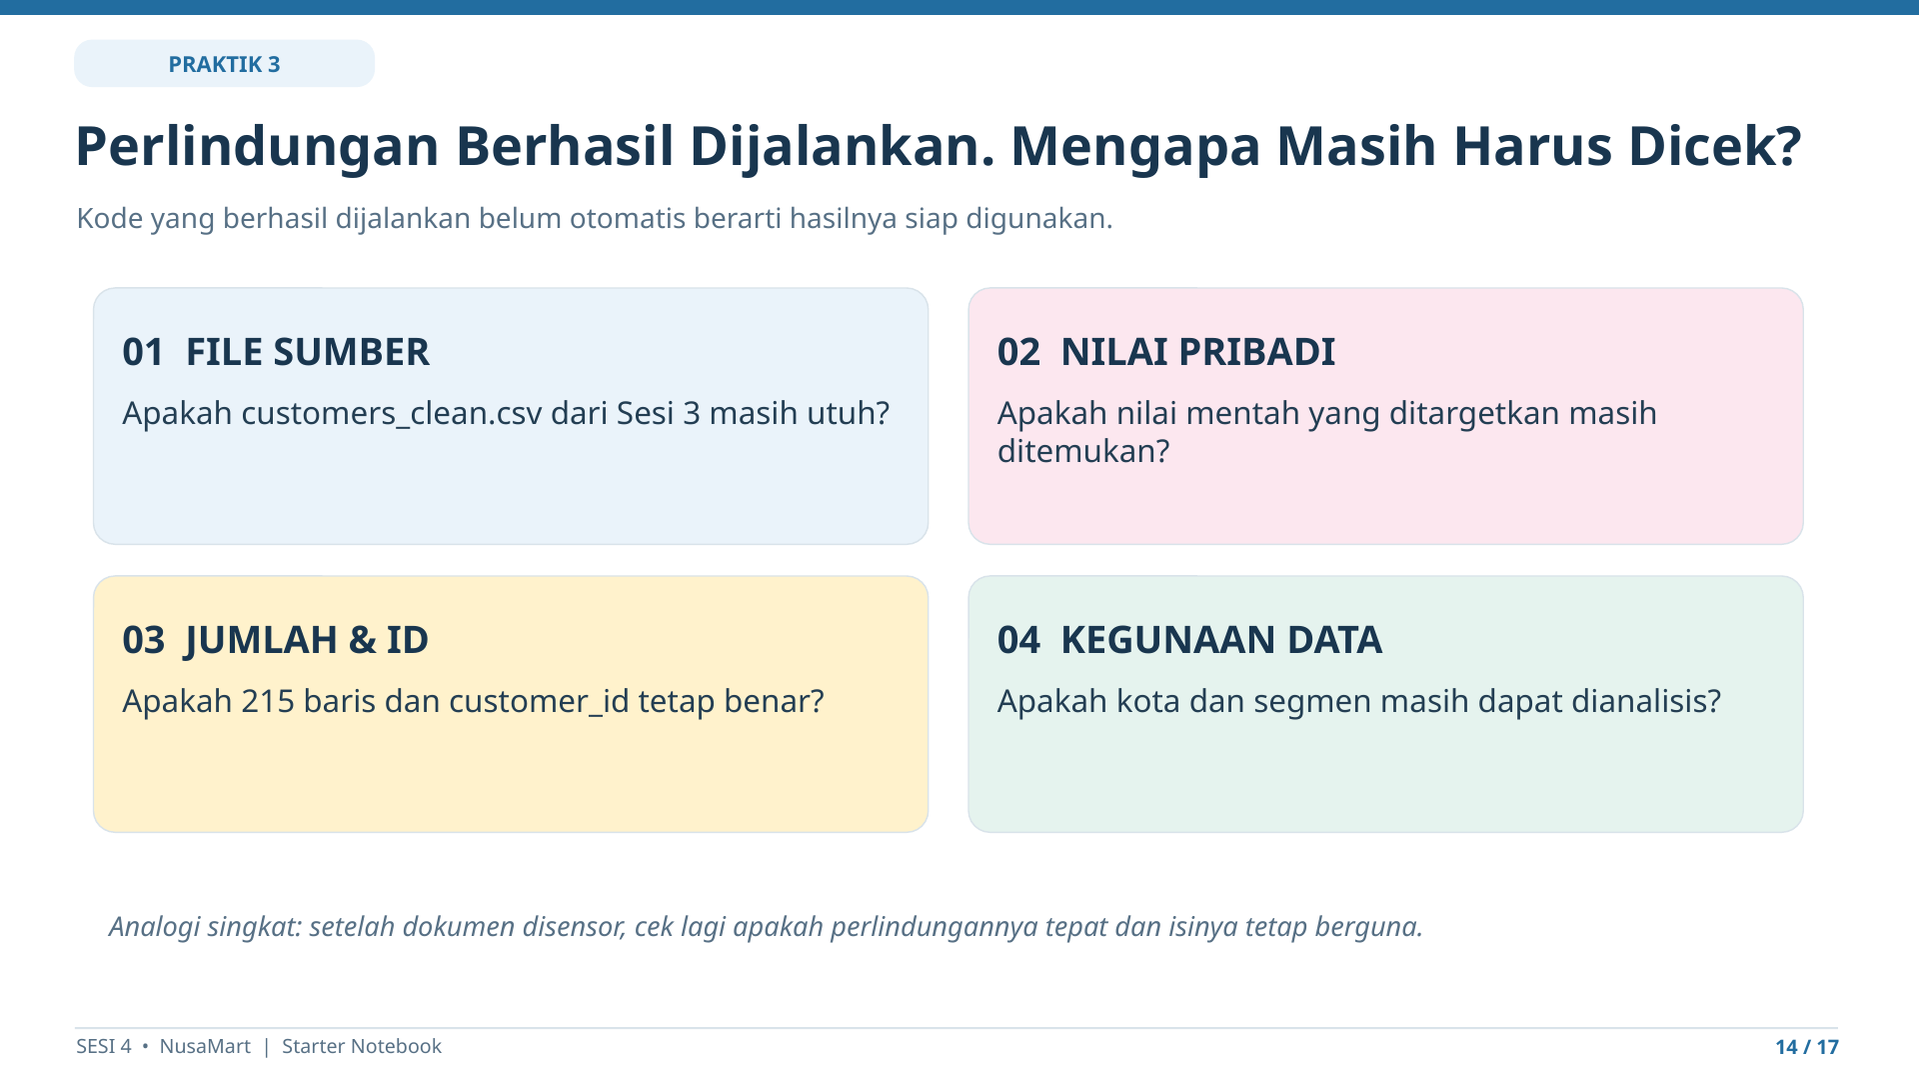


### Langkah 9 — RUN empat Section pemeriksaan, lalu catat enam tes

**Jalankan bertahap, bukan Run All:**

| Section | Pertanyaan yang dijawab | Catat pada Excel |
|---|---|---|
| **10** | Apakah sumber S3 masih sama? | **VT-02 / D7:E7** |
| **11** | Apakah nilai asli yang ditargetkan ditemukan lagi? | **VT-01 / D6:E6** |
| **12** | Apakah jumlah baris dan `customer_id` tetap benar? | **VT-03 / D8:E8** dan **VT-04 / D9:E9** |
| **13** | Apakah kota, segmen, dan status masih berguna? | **VT-06 / D11:E11** |

**Cara RECORD:** gunakan kolom **D** untuk hasil yang muncul, pilih **E** = `PASS` / `FAIL` / `NEEDS REVIEW` sesuai pemeriksaan, dan isi **F** jika ada masalah. **Hasil yang seharusnya sudah ada di kolom C.**

**Jika FAIL/NOT READY:** jangan memaksa Excel PASS. Baca penyebabnya, periksa keputusan Section 5, dan ikuti pesan pemeriksaan dan minta bantuan trainer jika belum berhasil.


#### **Panduan Visual — Langkah 9: Periksa Keamanan dan Kegunaan** — RUN Section 10–13 dan baca masing-masing hasilnya

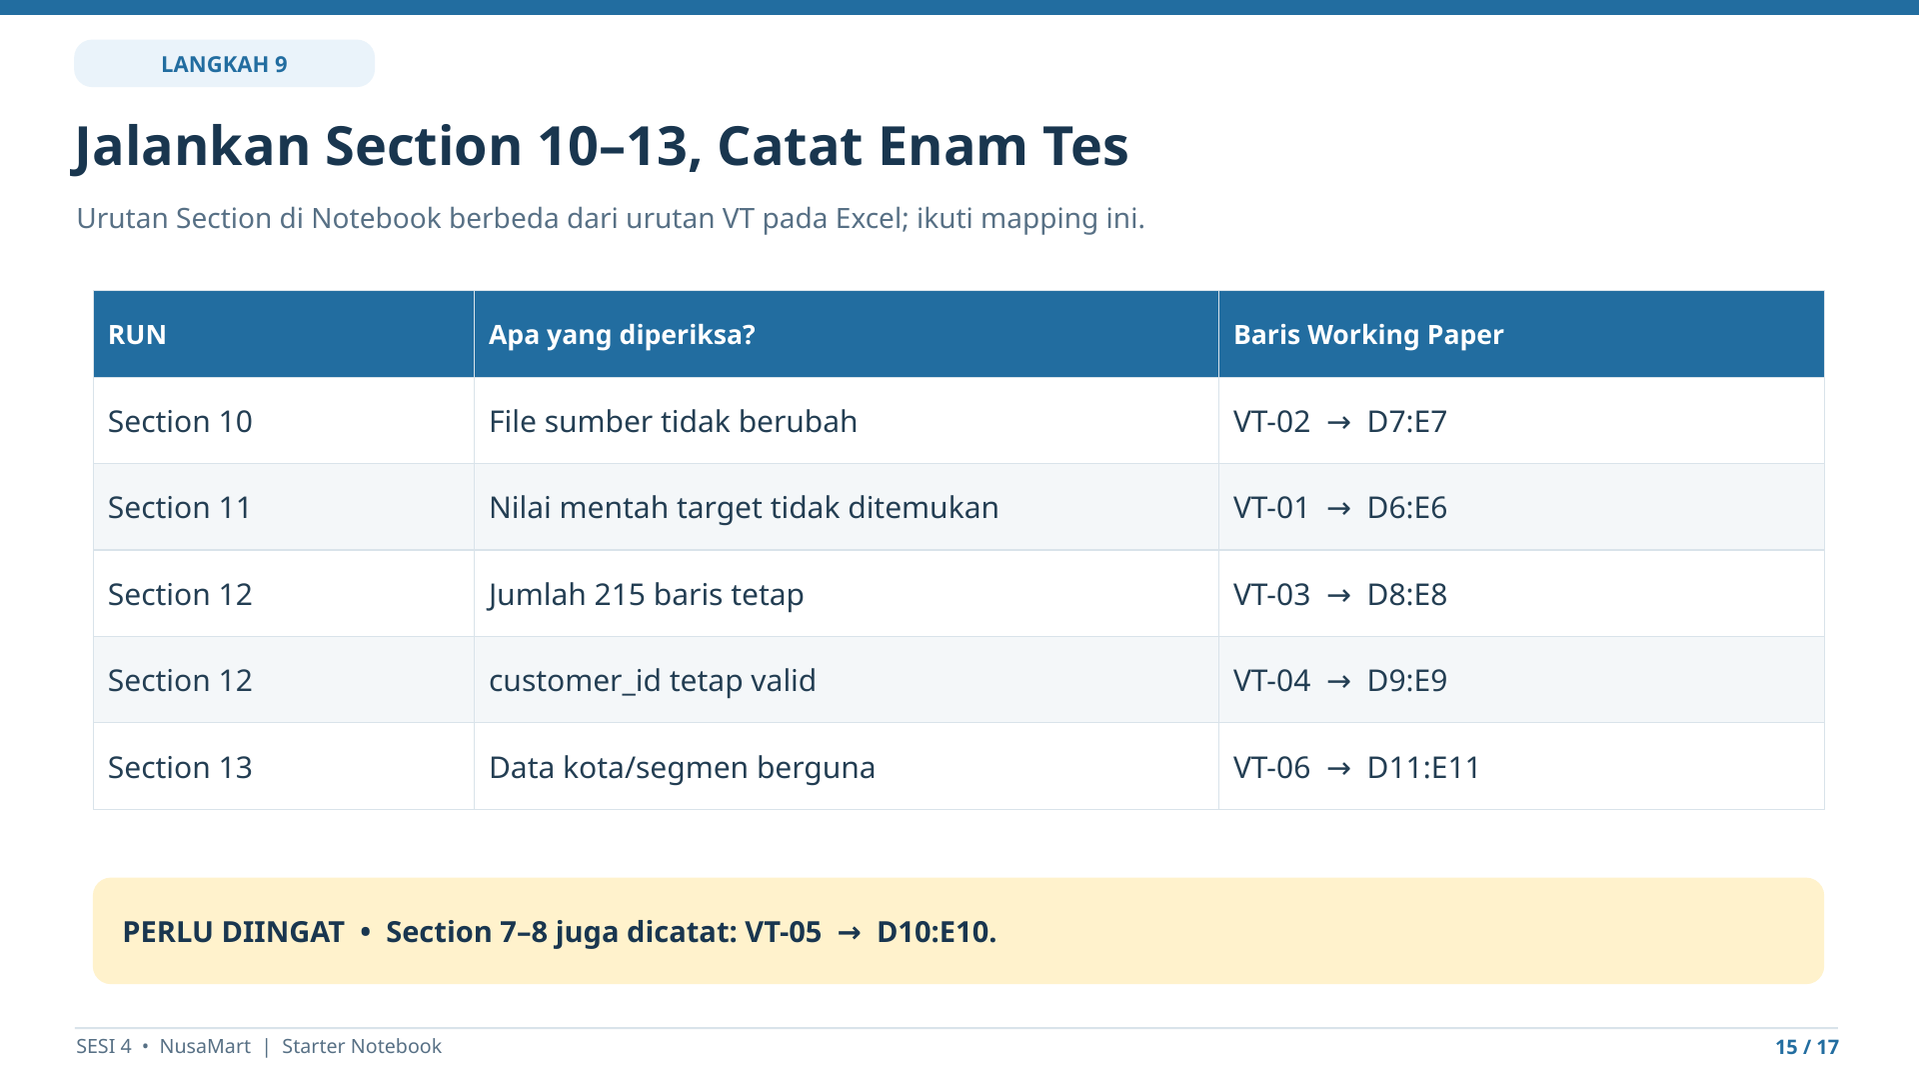


### Section 10 — Periksa apakah file bersih S3 berubah

**Tujuan:** memastikan `customers_clean.csv` masih sama dengan kondisi awal dari Section 2. File bersih ini penting untuk proses integrasi pada Sesi 5.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `SOURCE INTEGRITY: PASS` jika file tidak berubah.

📝 **RECORD → `03_Verification_Evidence`, VT-02 / D7:E7:** **D7** = hasil aktual, **E7** = status sesuai output. **F7** hanya jika ada masalah. Jangan mengisi PASS sebelum RUN.


In [12]:
if not review_gate_pass:
    source_integrity_pass = False
    print("SECTION 10 SKIPPED — REVIEW GATE belum PASS.")
else:
    source_snapshot_after = {
        "path": str(INPUT_PATH.relative_to(PROJECT_ROOT)),
        "rows": int(len(read_csv_robust(INPUT_PATH)[0])),
        "file_sha256": file_sha256(INPUT_PATH),
        "file_size_bytes": int(INPUT_PATH.stat().st_size),
    }

    source_integrity_pass = (
        source_snapshot_before["file_sha256"] == source_snapshot_after["file_sha256"]
        and source_snapshot_before["file_size_bytes"] == source_snapshot_after["file_size_bytes"]
        and source_snapshot_before["rows"] == source_snapshot_after["rows"]
    )

    print("SOURCE INTEGRITY:", "PASS" if source_integrity_pass else "FAIL")
    if not source_integrity_pass:
        print("Source fingerprint berubah. Jangan lanjut sebelum source S3 dipulihkan.")

SOURCE INTEGRITY: PASS


#### Sesudah RUN Section 10 — Catat keutuhan file sumber (VT-02)

**Contoh output jika berhasil:** `SOURCE INTEGRITY: PASS`.

- 🔵 **CHECK — Artinya:** Notebook membandingkan pengenal file asli dengan catatan yang dibuat di Section 2. Ini seperti memastikan dokumen asli masih sama setelah salinannya diolah.
- **Jika `FAIL`:** jangan mengubah Excel menjadi PASS. Periksa apakah file sumber S3 tertimpa atau berubah; hentikan proses dan cari sumber clean asli yang benar bersama trainer.
- 📝 **RECORD → `03_Verification_Evidence` VT-02 / baris 7:** **D7** tulis hasil aktual (`SOURCE INTEGRITY: PASS` jika benar muncul); **E7** pilih status yang sesuai; **F7** catat masalah jika perlu. PASS ini hanya membuktikan keutuhan file pada tes tersebut.


### Section 11 — Periksa kebocoran nilai pribadi yang ditargetkan

**Tujuan:** Notebook membandingkan nilai mentah lengkap yang ditargetkan dengan output protected, tanpa mencetak nilai pribadi mentah tersebut.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `LEAK CHECK: PASS` jika nilai target tidak ditemukan. Hasil ini **terbatas pada pemeriksaan yang dibuat**, bukan uji anonimitas menyeluruh.

📝 **RECORD → `03_Verification_Evidence`, VT-01 / D6:E6.** Isi **F6** hanya jika ada masalah.


In [13]:
# 🟢 RUN — leak check nilai mentah lengkap, tidak mencetak PII aktual.
leak_check_table=None
leak_check_pass=False
if not review_gate_pass:
    print('SECTION 11 SKIPPED — REVIEW GATE belum PASS.')
else:
    protected_cell_values=[]
    for col in protected.columns:
        protected_cell_values.extend(protected[col].dropna().astype(str).tolist())
    leaked=[]
    for field in EXPECTED_COLUMNS:
        if normalized_plan[field]['remove_raw']!='YES':continue
        raw_values=set(customers[field].dropna().astype(str).tolist())
        # Persis sama atau satu nilai asli lengkap tersisip di string protected lain.
        leak_count=sum(any(raw == cell or (len(raw)>=6 and raw in cell)
                           for cell in protected_cell_values) for raw in raw_values if raw)
        leaked.append({'field':field,'raw_unique_values_checked':len(raw_values),
                       'raw_values_found_in_protected_output':int(leak_count),
                       'status':'PASS' if leak_count==0 else 'FAIL'})
    leak_check_table=pd.DataFrame(leaked)
    mandatory={'customer_name','email','phone'}
    required_checked=mandatory.issubset(set(leak_check_table['field']) if not leak_check_table.empty else set())
    leak_check_pass=(required_checked and not leak_check_table.empty
                     and bool((leak_check_table['status']=='PASS').all()))
    print('LEAK CHECK:', 'PASS' if leak_check_pass else 'FAIL / NEEDS REVIEW')
    display(leak_check_table)
    if not required_checked:print('AKSI: raw customer_name/email/phone wajib dilindungi; periksa Section 5.')

LEAK CHECK: PASS


,field,raw_unique_values_checked,raw_values_found_in_protected_output,status
0,customer_name,171,0,PASS
1,join_date,188,0,PASS
2,email,215,0,PASS
3,phone,215,0,PASS


#### Sesudah RUN Section 11 — Catat pemeriksaan nilai pribadi (VT-01)

**Contoh output jika berhasil:** `LEAK CHECK: PASS` dan tabel `field`, `raw_unique_values_checked`, `raw_values_found_in_protected_output`, `status`.

- 🔵 **CHECK — Artinya:** Notebook mencoba menemukan **nilai mentah lengkap yang menjadi target** pada data terlindungi. `raw_unique_values_checked` adalah jumlah nilai asli berbeda yang diperiksa; `raw_values_found_in_protected_output` menunjukkan berapa nilai yang ditemukan lagi. Jika 0 untuk seluruh target wajib dan status lulus, tes ini PASS.
- **Batasnya:** tes ini **tidak membuktikan seluruh kemungkinan identifikasi ulang telah dihilangkan**. Hashing atau masking bukan jaminan anonim sempurna.
- **Jika `FAIL / NEEDS REVIEW`:** periksa field yang gagal, kembali ke keputusan dan teknik Section 5 lalu jalankan ulang perlindungan dan tes. Jangan memaksa status Excel menjadi PASS.
- 📝 **RECORD → `03_Verification_Evidence` VT-01 / baris 6:** **D6** hasil aktual (`LEAK CHECK: PASS` hanya jika benar muncul); **E6** pilih status; **F6** isi masalah bila ada.


### Section 12 — Periksa jumlah pelanggan dan kunci `customer_id`

**Mengapa diperiksa?** Dataset NusaMart harus mempertahankan **215 baris** dan `customer_id` yang benar agar analisis serta penggabungan data pada Sesi 5 tetap memungkinkan.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `KEY / RECORD INTEGRITY: PASS` dan lihat baris hasil `row_count_preserved`, `customer_id_present`, `customer_id_unique`, `customer_id_no_null`, serta `customer_id_unchanged`.

📝 **RECORD:** dua tes dalam satu Section — **VT-03 / D8:E8** untuk jumlah baris, **VT-04 / D9:E9** untuk integritas `customer_id`.


In [14]:
key_record_checks = {}
key_record_pass = False

if not review_gate_pass:
    print("SECTION 12 SKIPPED — REVIEW GATE belum PASS.")
else:
    key_record_checks = {
        "row_count_preserved": len(protected) == len(customers),
        "customer_id_present": "customer_id" in protected.columns,
        "customer_id_non_null": (
            "customer_id" in protected.columns and protected["customer_id"].notna().all()
        ),
        "customer_id_unique": (
            "customer_id" in protected.columns and not protected["customer_id"].duplicated().any()
        ),
        "customer_id_values_preserved": (
            "customer_id" in protected.columns
            and protected["customer_id"].astype(str).tolist() == customers["customer_id"].astype(str).tolist()
        ),
    }

    key_record_pass = all(key_record_checks.values())
    display(pd.DataFrame(
        [{"check": k, "pass": v} for k, v in key_record_checks.items()]
    ))
    print("KEY / RECORD INTEGRITY:", "PASS" if key_record_pass else "FAIL")

,check,pass
0,row_count_preserved,True
1,customer_id_present,True
2,customer_id_non_null,True
3,customer_id_unique,True
4,customer_id_values_preserved,True


KEY / RECORD INTEGRITY: PASS


#### Sesudah RUN Section 12 — Dua tes dari satu output (VT-03 dan VT-04)

**Contoh output jika berhasil:** tabel `check` / `pass` berisi nilai `True` dan teks `KEY / RECORD INTEGRITY: PASS`.

| Yang dibaca pada output | Maknanya | Catat di |
|---|---|---|
| `row_count_preserved = True` | Jumlah baris pada salinan tetap seperti file sumber (215 baris pada dataset latihan). | **VT-03: D8/E8** |
| `customer_id_present`, `customer_id_non_null`, `customer_id_unique`, `customer_id_values_preserved` seluruhnya `True` | Kunci pelanggan masih ada, tidak kosong, unik, dan nilainya tidak berubah. | **VT-04: D9/E9** |

- 🔵 **CHECK — Artinya:** File tetap dapat dihubungkan dengan data NusaMart lainnya menggunakan `customer_id`, dengan izin yang sesuai. *Bukan* berarti ID bebas dibagikan.
- **Jika ada `False`:** tes yang berkaitan harus FAIL atau NEEDS REVIEW di Excel; periksa Section 5 dan hentikan finalisasi sebelum diperbaiki.
- 📝 **RECORD:** `03_Verification_Evidence` → **D8:E9**. Tulis ringkasan hasil nyata pada D8 dan D9, pilih status aktual di E8/E9, beri alasan di F8/F9 jika gagal.


### Section 13 — Periksa apakah data masih berguna untuk analisis

**Tujuan NusaMart:** menghitung distribusi pelanggan berdasarkan kota dan segmen. Jika informasi ini rusak atau hilang, perlindungan saja belum cukup.

🟢 **RUN** tanpa EDIT.

🔵 **CHECK:** `ANALYTICAL UTILITY: PASS`. Tabel memeriksa bahwa informasi `city`, `customer_segment`, `customer_status` masih sesuai dengan pemeriksaan kegunaan dasar latihan.

📝 **RECORD → `03_Verification_Evidence`, VT-06 / D11:E11.** Isi F11 bila hasil tidak sesuai.


In [15]:
# 🟢 RUN — cek utility dasar terhadap tujuan distribusi pelanggan.
utility_table=None;utility_pass=False
if not review_gate_pass:
    print('SECTION 13 SKIPPED — REVIEW GATE belum PASS.')
else:
    utility_rows=[]
    for field in sorted(REQUIRED_ANALYTIC_COLUMNS):
        present=field in protected.columns
        b=int(customers[field].notna().sum())
        a=int(protected[field].notna().sum()) if present else 0
        categories=int(protected[field].nunique(dropna=True)) if present else 0
        group_usable=present and categories>=1
        preserved=present and b==a
        check_status=bool(preserved and group_usable)
        if field=='customer_status' and present:
            check_status=check_status and protected[field].equals(customers[field])
        utility_rows.append({'field':field,'present_after':present,'before_non_null':b,
            'after_non_null':a,'categories_after':categories,'pass':check_status})
    utility_table=pd.DataFrame(utility_rows)
    utility_pass=bool(utility_table['pass'].all())
    display(utility_table)
    print('ANALYTICAL UTILITY:', 'PASS' if utility_pass else 'FAIL')
    if not utility_pass:print('AKSI: cek Section 5, jangan hilangkan field analitik utama.')

,field,present_after,before_non_null,after_non_null,categories_after,pass
0,city,True,215,215,10,True
1,customer_segment,True,211,211,4,True
2,customer_status,True,215,215,2,True


ANALYTICAL UTILITY: PASS


#### Sesudah RUN Section 13 — Apakah data masih berguna untuk analisis? (VT-06)

**Contoh output jika berhasil:** tabel kondisi `city`, `customer_segment`, `customer_status` dan teks `ANALYTICAL UTILITY: PASS`.

- 🔵 **CHECK — Artinya:** Kolom yang dibutuhkan untuk distribusi pelanggan masih tersedia dan lolos cek dasar jumlah data terisi serta jumlah kategori. `present_after` artinya kolom ada, `after_non_null` jumlah yang terisi sesudah perlindungan, `categories_after` jumlah kategori tersisa, `pass` status per field.
- **Batasnya:** PASS mengonfirmasi kriteria utilitas **latihan ini**, bukan seluruh kebutuhan analisis dunia kerja.
- **Jika `FAIL`:** periksa apakah ada kolom yang hilang, nilai kosong berubah, atau kategori tidak lagi berguna. Kembali ke keputusan Section 5 lalu RUN perlindungan dan pemeriksaan lagi.
- 📝 **RECORD → `03_Verification_Evidence` VT-06 / baris 11:** **D11** hasil aktual/ringkasan kolom analitik, **E11** status sesuai output, **F11** catatan masalah bila ada.


### Langkah 10 — Simpan bukti dan selesaikan Sesi 4

1. Periksa kembali hasil Section 10–13. Pastikan tidak ada tes yang FAIL atau tertinggal.
2. Jalankan **Section 14** untuk menyimpan file hasil dan bukti pendukung **jika seluruh syarat sudah terpenuhi**.
3. Jalankan **Section 15** untuk pemeriksaan akhir.
4. Buka Excel → `03_Verification_Evidence`. Pastikan **VT-01–VT-06 di baris 6–11** sudah memiliki **kolom D (hasil aktual)** dan **kolom E (status)** yang sesuai. Contoh pada **baris 17** hanya ilustrasi, **bukan salah satu enam tes**.
5. Lihat status ringkasan **E13**: `READY` berarti enam hasil tes telah dicatat sebagai PASS. **Status ini tidak menggantikan Final Quality Gate Notebook.**
6. Simpan dua file: **`S4_NusaMart_Safe_Data_Starter.ipynb`** dan **`S4_NusaMart_Safe_Data_Working_Paper.xlsx`**.

🔵 **CHECK:** `EVIDENCE SAVED: PASS`, `FINAL QUALITY GATE: PASS`, `S4 PARTICIPANT STARTER: COMPLETE`.

📝 **RECORD:** tidak menambah output resmi baru. File CSV/JSON di folder hasil merupakan **bukti pendukung**, bukan berkas submission tambahan yang wajib.


#### Panduan visual — Langkah 10 — Catat enam tes pemeriksaan

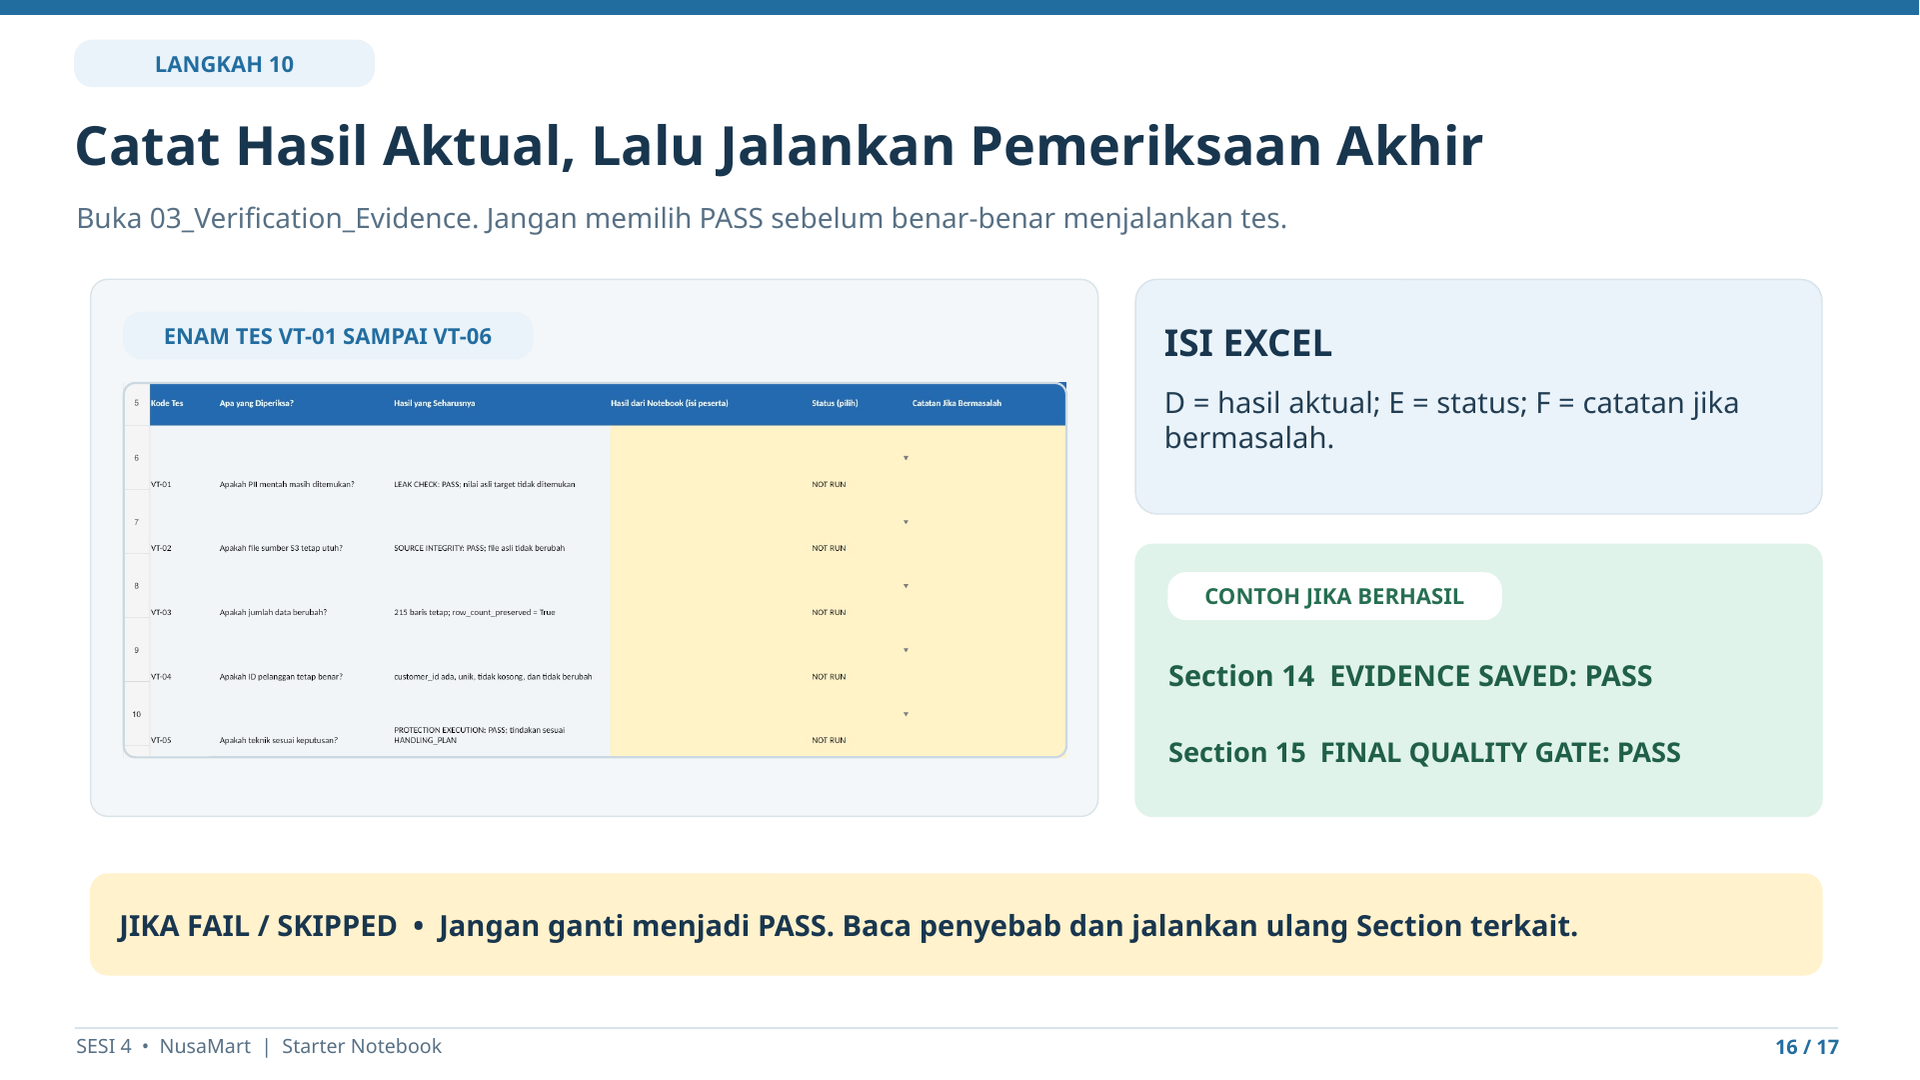

### Section 14 — Simpan hasil perlindungan dan bukti pemeriksaan

**Apa yang dilakukan kode?** Setelah seluruh gate teknis lulus, Notebook menyimpan tiga file pendukung pada `outputs/sesi_04/`:
- `customers_protected_preview.csv` (salinan data hasil perlindungan),
- `s4_validation_summary.csv` (ringkasan hasil tes),
- `s4_verification_evidence.json` (catatan pemeriksaan).

🟢 **RUN** hanya setelah Section 10–13 PASS. 🔵 **CHECK:** `EVIDENCE SAVED: PASS`.

📝 **RECORD:** **tidak perlu menambah baris baru di Excel**. Pastikan hasil VT-01–VT-06 sudah dicatat. **Tiga file pendukung ini bukan output resmi tambahan.**


In [16]:
# 🟢 RUN — simpan hanya setelah semua gate dasar benar-benar PASS.
EVIDENCE_JSON_PATH=OUTPUT_DIR/'s4_verification_evidence.json'
VALIDATION_CSV_PATH=OUTPUT_DIR/'s4_validation_summary.csv'
evidence_saved=False
if not review_gate_pass:
    print('SECTION 14 SKIPPED — REVIEW GATE belum PASS.')
elif not all([source_integrity_pass,leak_check_pass,key_record_pass,utility_pass]):
    print('EVIDENCE SAVED: BLOCKED — masih ada verification FAIL. Perbaiki keputusan lalu RUN lagi dari Section 5.')
else:
    protected.to_csv(PROTECTED_OUTPUT_PATH,index=False,encoding='utf-8-sig')
    protected_output_saved=PROTECTED_OUTPUT_PATH.is_file()
    validation_summary=pd.DataFrame([
        {'check':'review_gate','status':'PASS'},
        {'check':'source_integrity','status':'PASS'},
        {'check':'leak_check','status':'PASS'},
        {'check':'key_record_integrity','status':'PASS'},
        {'check':'analytical_utility','status':'PASS'},
    ])
    validation_summary.to_csv(VALIDATION_CSV_PATH,index=False,encoding='utf-8-sig')
    evidence_payload={
       'session':'S4','case':'NusaMart Safe Data','source':source_snapshot_before,
       'handling_plan':normalized_plan,'agent_permissions_simulated':normalized_permissions,
       'protected_output':str(PROTECTED_OUTPUT_PATH.relative_to(PROJECT_ROOT)),
       'validation':{k:True for k in ['review_gate','source_integrity','leak_check','key_record_integrity','analytical_utility']},
       'caution':'Masking and hashing are not equivalent to anonymization. Access permissions are documented, not enforced by this Notebook.',
       'note':'Supporting evidence only. Official outputs: Audit PII, Ethics Checklist, Tested Masking Script.'
    }
    with open(EVIDENCE_JSON_PATH,'w',encoding='utf-8') as f:
        json.dump(evidence_payload,f,ensure_ascii=False,indent=2)
    evidence_saved=all(p.is_file() for p in [PROTECTED_OUTPUT_PATH,VALIDATION_CSV_PATH,EVIDENCE_JSON_PATH])
    print('EVIDENCE SAVED:', 'PASS' if evidence_saved else 'FAIL')
    print('Folder:', OUTPUT_DIR)
    print('File:',PROTECTED_OUTPUT_PATH.name,VALIDATION_CSV_PATH.name,EVIDENCE_JSON_PATH.name)

EVIDENCE SAVED: PASS
Folder: C:\Bootcamp\Bootcamp_Data_Analyst\outputs\sesi_04
File: customers_protected_preview.csv s4_validation_summary.csv s4_verification_evidence.json


#### Sesudah RUN Section 14 — File pendukung berhasil disimpan?

**Contoh output jika berhasil:** `EVIDENCE SAVED: PASS` dan lokasi folder `outputs/sesi_04`.

- 🔵 **CHECK — Artinya:** Karena Review Gate dan seluruh tes wajib lulus, Notebook menyimpan **tiga berkas bukti pendukung**: `customers_protected_preview.csv`, `s4_validation_summary.csv`, dan `s4_verification_evidence.json`.
- **Jika `EVIDENCE SAVED: BLOCKED`:** ada tes yang belum lulus. Periksa output Section 10–13 lalu perbaiki masalah. Jangan memaksa penyimpanan secara manual atau menyebarkan file mentah.
- 📝 **RECORD:** **CHECK SAJA**. Tidak perlu menambah baris atau output resmi. Periksa kembali bahwa VT-01–VT-06 di `03_Verification_Evidence` dicatat dari RUN yang sebenarnya.


### Section 15 — Pemeriksaan akhir pekerjaan

**Apa yang dilakukan kode?** Menyatukan hasil Review Gate, perlindungan data, pemeriksaan sumber, kebocoran target, jumlah/ID, kegunaan analisis, dan penyimpanan evidence.

🟢 **RUN** setelah Section 14. **Jangan EDIT**.

🔵 **CHECK:** `FINAL QUALITY GATE: PASS` dan `S4 PARTICIPANT STARTER: COMPLETE` berarti pemeriksaan teknis yang disyaratkan untuk latihan ini terpenuhi.

📝 **RECORD:** cocokkan enam baris **`03_Verification_Evidence!D6:E11`** dengan hasil Notebook yang benar. `PASS` hanya berarti tes terkait memenuhi syaratnya.


In [17]:
# 🟢 RUN — final gate setelah semua evidence berhasil disimpan.
final_checks={
 'Review decisions complete':bool(review_gate_pass),
 'Protected evidence saved':bool(protected_output_saved),
 'Source unchanged':bool(source_integrity_pass) if review_gate_pass else False,
 'Raw-value leak check':bool(leak_check_pass) if review_gate_pass else False,
 'Key & record integrity':bool(key_record_pass) if review_gate_pass else False,
 'Analytical utility':bool(utility_pass) if review_gate_pass else False,
 'Verification evidence saved':bool(evidence_saved),
}
final_gate_pass=all(final_checks.values())
display(pd.DataFrame([{'check':k,'status':'PASS' if v else 'NOT PASS'} for k,v in final_checks.items()]))
if final_gate_pass:
    print('FINAL QUALITY GATE: PASS')
    print('S4 PARTICIPANT STARTER: COMPLETE')
    print('RECORD: isikan status validasi ke 03_Verification_Evidence. Jangan kirim data PII mentah.')
else:
    print('FINAL QUALITY GATE: NOT READY')
    print('AKSI: kembali ke Section 5 jika keputusan belum PASS atau periksa check Section 10–13.')

,check,status
0,Review decisions complete,PASS
1,Protected evidence saved,PASS
2,Source unchanged,PASS
3,Raw-value leak check,PASS
4,Key & record integrity,PASS
5,Analytical utility,PASS
6,Verification evidence saved,PASS


FINAL QUALITY GATE: PASS
S4 PARTICIPANT STARTER: COMPLETE
RECORD: isikan status validasi ke 03_Verification_Evidence. Jangan kirim data PII mentah.


#### Sesudah RUN Section 15 — Pemeriksaan akhir dan penyelesaian

**Contoh output jika berhasil:** `FINAL QUALITY GATE: PASS` dan `S4 PARTICIPANT STARTER: COMPLETE`.

- 🔵 **CHECK — Artinya:** Notebook menggabungkan hasil Review Gate, perlindungan, keutuhan sumber, pemeriksaan nilai mentah, keutuhan jumlah/ID, kegunaan data, dan penyimpanan bukti. Hanya jika semuanya lulus, status akhir menjadi PASS.
- **Jika `FINAL QUALITY GATE: NOT READY`:** lihat baris pada tabel `check` / `status` yang bertuliskan `NOT PASS`. Kembali ke Section terkait dan jalankan ulang secara berurutan; jangan mengubah nilai di Working Paper menjadi PASS jika output tidak mendukungnya.
- 📝 **RECORD:** buka `03_Verification_Evidence` **D6:E11** dan pastikan keenam catatan sesuai hasil aktual. Kolom F untuk catatan kendala, G referensi Section yang sudah tersedia. Simpan dua file utama: Notebook dan Working Paper.
- **Batas keamanan:** PASS adalah hasil pemeriksaan teknis yang dirancang untuk latihan. Data terlindungi tetap harus digunakan dengan izin dan kehati-hatian.


### Hasil Praktik — apa yang wajib diselesaikan?

**Tiga output resmi Lesson Plan S4 tetap:**

1. **Catatan Audit PII** → `01_PII_Audit` (delapan field dengan risiko, alasan, usulan).
2. **Checklist Etika Data** → `02_Ethics_Permission` (keputusan penggunaan dan izin Agent).
3. **Skrip Masking PII Teruji** → Notebook ini, setelah perlindungan dan pemeriksaan dijalankan. Catatan VT pada `03_Verification_Evidence` adalah bukti pendukung output ketiga.

**Periksa sebelum keluar breakout:**

- [ ] Pada Praktik 1, seluruh **B6:E13** terisi dan F15 menunjukkan `READY`.
- [ ] Pada Praktik 2, seluruh keputusan **B6:D13** dan izin **B18:D21** yang perlu diisi sudah lengkap.
- [ ] Notebook menampilkan `REVIEW GATE: PASS` dan `FINAL QUALITY GATE: PASS`.
- [ ] VT-01–VT-06 pada Praktik 3 **D6:E11** telah dicatat dari output aktual (bukan dari contoh).
- [ ] Simpan dua file utama: `S4_NusaMart_Safe_Data_Working_Paper.xlsx` dan `S4_NusaMart_Safe_Data_Starter.ipynb`.

**Untuk Sesi 5:** sumber `customers_clean.csv` dari S3 tetap dijaga; `customer_id` tetap tersedia untuk menghubungkan data dengan izin yang sesuai. Protected preview S4 adalah hasil latihan, **bukan otomatis pengganti data integrasi S5**.

> **Pengingat keamanan:** data pribadi mentah tidak boleh dikirim ke layanan AI, internet, atau screenshot yang dibagikan. Pemeriksaan latihan mengurangi risiko tertentu, bukan menjamin anonimitas total.


#### **Panduan Visual — Hasil Praktik: Apa Saja Hasil Sesi 4?** — Tiga output resmi dan checklist akhir

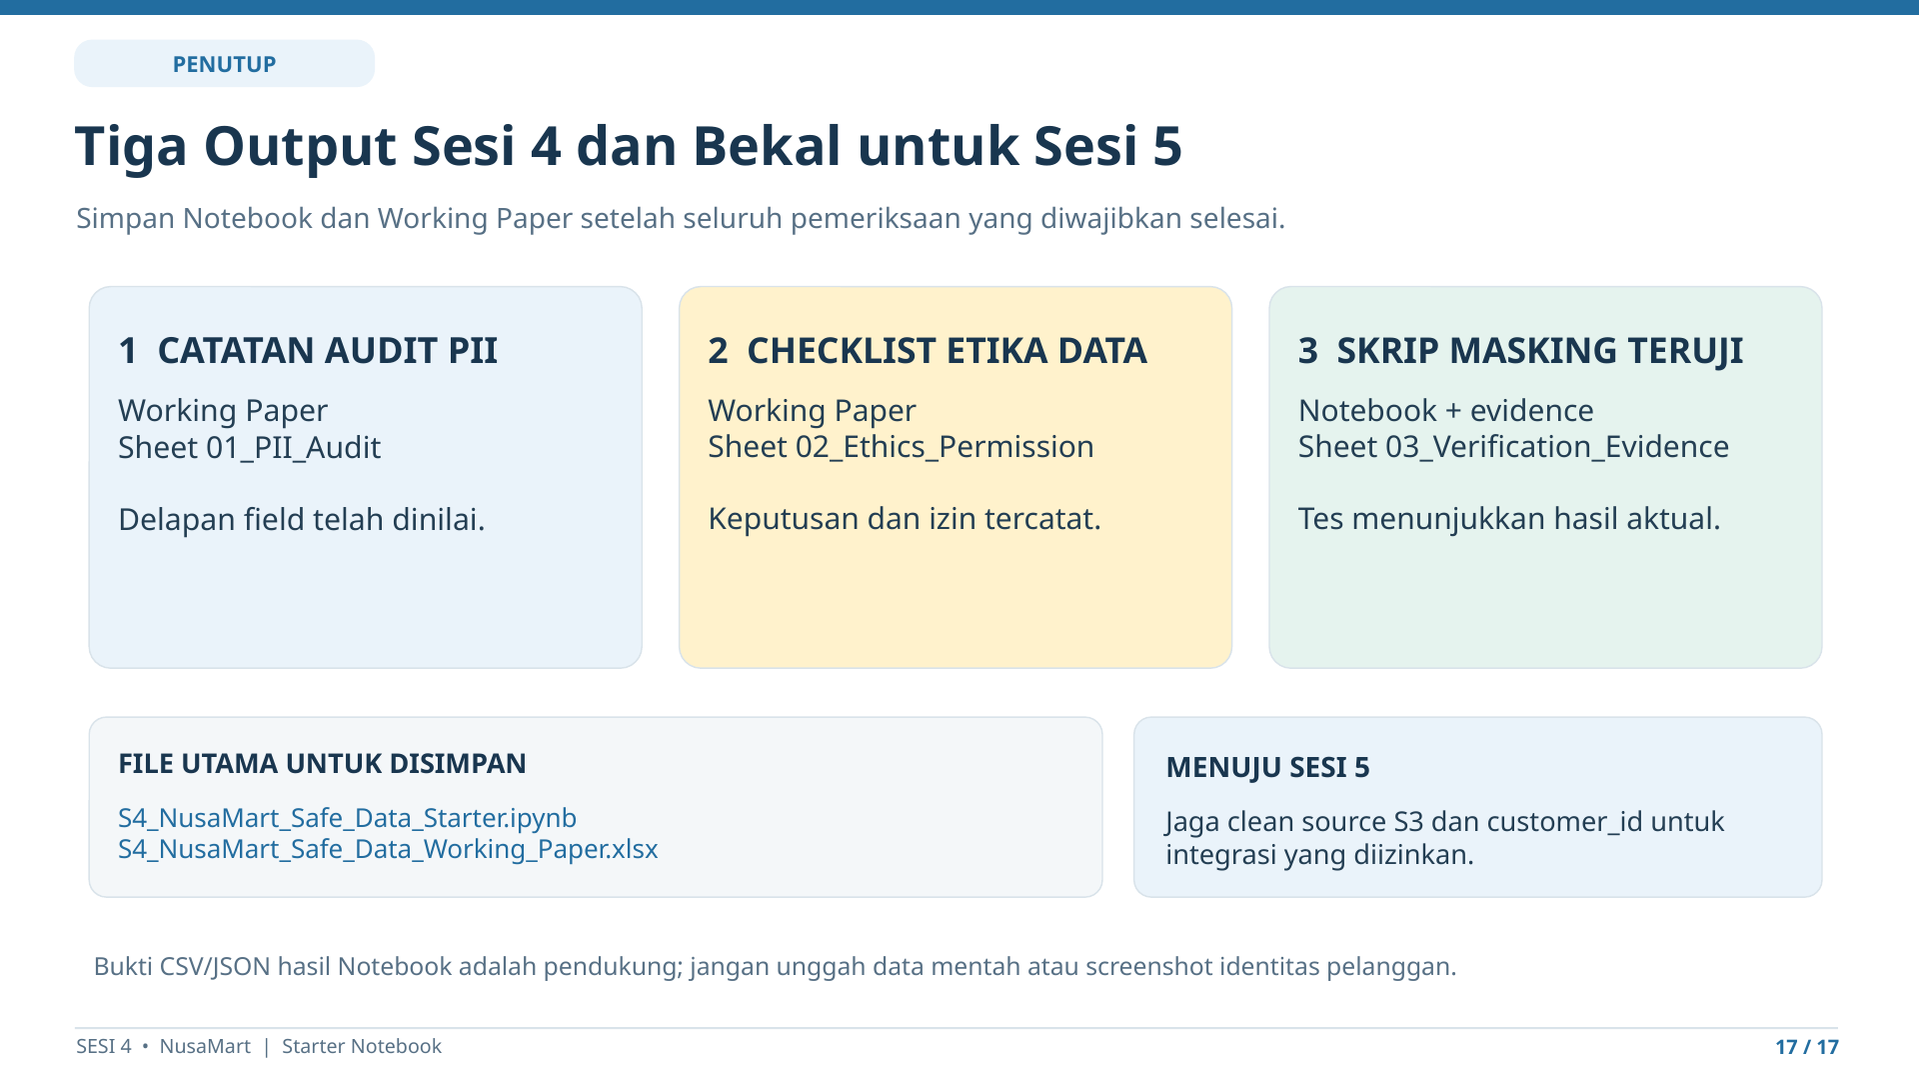
